# Delivery Time Estimation: Exploratory Data Analysis (EDA)

**Hackathon:** Machine Learning Regression Model for Predictive Analytics, Option C (Delivery Time Estimation)

Run the cells one by one from top to bottom (Shift + Enter). Run each cell only once. If something goes wrong, use "Restart and run all".

<br>

## About this project

**The problem.** Every food delivery app shows the customer an estimated delivery time. If the estimate is too short, the order arrives "late" and the customer is unhappy. If it is too long, the customer may not order at all. The company also uses expected delivery time to decide which rider gets which order. So an accurate estimate has a clear business value.

**What we predict.** Delivery time in minutes. It is a continuous number, so this is a regression problem.

**When we predict.** At the moment an order is assigned to a rider. At that point we know the rider, vehicle, order, weather, traffic, city and locations, but not the pickup time. So pickup time is never used as a model input (that would be data leakage).

<br>

## Where the data comes from

| Item | Detail |
|---|---|
| Source | Kaggle, "Food Delivery Dataset" by Gaurav Malik |
| Link | https://www.kaggle.com/datasets/gauravmalik26/food-delivery-dataset |
| Origin | First released for a HackerEarth machine learning competition |
| File used | `zomato_dataset.csv` (a lightly pre-cleaned copy; all 45,584 order IDs match the Kaggle original) |
| Size | 45,584 orders, 20 columns |
| Period | 11 Feb 2022 to 6 Apr 2022 |
| Places | 22 Indian cities, 3 city types |

<br>

## Why this dataset

Option C says: estimate delivery time "based on route, traffic, courier characteristics, and package type". The dataset has columns for each one:

| Option C asks for | Columns in the dataset |
|---|---|
| Route | Restaurant and delivery latitude / longitude, city type |
| Traffic | Road traffic density, weather, festival |
| Courier characteristics | Rider age, rider rating, vehicle type, vehicle condition, multiple deliveries |
| Package type | Type of order (Snack, Meal, Drinks, Buffet) |
| Target | Time taken in minutes |

<br>

## Data pipeline in this notebook

```
Kaggle CSV
   -> Step 1: Load + schema check
   -> Step 2: Data quality audit (find problems)
   -> Step 3: Clean data (fix problems)  -> data/processed/clean_data.csv
   -> Step 4: EDA (charts + findings)
   -> Next notebook: feature engineering, models, evaluation, app
```

## Step 0: Setup

In [1]:
# os lets us check whether a file exists and create folders
import os

# numpy for maths, pandas for working with tables
import numpy as np
import pandas as pd

# matplotlib and seaborn for charts
import matplotlib.pyplot as plt
import seaborn as sns

# white background with light grid lines for every chart
sns.set_theme(style="whitegrid")

# one colour for all charts so they look like one set
COLOR = "#3B6EA5"

# show every column when a table is printed
pd.set_option("display.max_columns", 50)

In [2]:
# On your laptop the CSV sits inside the data/raw/ folder
DATA_PATH = "data/raw/zomato_dataset.csv"

# In Google Colab: upload zomato_dataset.csv using the folder icon on the left.
# The file then sits next to the notebook, so we use just the file name.
if not os.path.exists(DATA_PATH):
    DATA_PATH = "zomato_dataset.csv"

print("Reading data from:", DATA_PATH)

Reading data from: data/raw/zomato_dataset.csv


## Step 1: Load the data and check its structure

Questions: Does the file load? Are all expected columns there? What type is each column? How much is missing? Any duplicates?

In [3]:
# read the CSV file into a table (a DataFrame)
raw = pd.read_csv(DATA_PATH)

# shape gives (rows, columns)
print("Rows:", raw.shape[0], "| Columns:", raw.shape[1])

Rows: 45584 | Columns: 20


In [4]:
# first 5 rows
raw.head()

,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weather_conditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken (min)
0,0xcdcd,DEHRES17DEL01,36.0,4.2,30.327968,78.046106,30.397968,78.116106,12-02-2022,21:55,22:10,Fog,Jam,2,Snack,motorcycle,3.0,No,Metropolitian,46
1,0xd987,KOCRES16DEL01,21.0,4.7,10.003064,76.307589,10.043064,76.347589,13-02-2022,14:55,15:05,Stormy,High,1,Meal,motorcycle,1.0,No,Metropolitian,23
2,0x2784,PUNERES13DEL03,23.0,4.7,18.562450,73.916619,18.652450,74.006619,04-03-2022,17:30,17:40,Sandstorms,Medium,1,Drinks,scooter,1.0,No,Metropolitian,21
3,0xc8b6,LUDHRES15DEL02,34.0,4.3,30.899584,75.809346,30.919584,75.829346,13-02-2022,09:20,09:30,Sandstorms,Low,0,Buffet,motorcycle,0.0,No,Metropolitian,20
4,0xdb64,KNPRES14DEL02,24.0,4.7,26.463504,80.372929,26.593504,80.502929,14-02-2022,19:50,20:05,Fog,Jam,1,Snack,scooter,1.0,No,Metropolitian,41


In [5]:
# Schema check: these are the 20 columns we expect in the file
EXPECTED_COLUMNS = [
    "ID", "Delivery_person_ID", "Delivery_person_Age", "Delivery_person_Ratings",
    "Restaurant_latitude", "Restaurant_longitude",
    "Delivery_location_latitude", "Delivery_location_longitude",
    "Order_Date", "Time_Orderd", "Time_Order_picked",
    "Weather_conditions", "Road_traffic_density", "Vehicle_condition",
    "Type_of_order", "Type_of_vehicle", "multiple_deliveries",
    "Festival", "City", "Time_taken (min)",
]

# list of expected columns that are NOT in the file
missing_columns = [col for col in EXPECTED_COLUMNS if col not in raw.columns]

# stop with a clear message if any column is missing
if len(missing_columns) > 0:
    raise ValueError("These columns are missing: " + str(missing_columns))

print("Schema check passed: all", len(EXPECTED_COLUMNS), "expected columns are present")

Schema check passed: all 20 expected columns are present


In [6]:
# One summary row per column
column_summary = pd.DataFrame({
    "data_type": raw.dtypes.astype(str),                  # number or text
    "missing_count": raw.isna().sum(),                    # empty cells
    "missing_percent": (raw.isna().mean() * 100).round(2),
    "unique_values": raw.nunique(),                       # how many different values
    "example_value": raw.iloc[0],                         # value in the first row
})

column_summary

,data_type,missing_count,missing_percent,unique_values,example_value
ID,str,0,0.00,45584,0xcdcd
Delivery_person_ID,str,0,0.00,1320,DEHRES17DEL01
Delivery_person_Age,float64,1854,4.07,22,36.0
Delivery_person_Ratings,float64,1908,4.19,28,4.2
Restaurant_latitude,float64,0,0.00,657,30.327968
Restaurant_longitude,float64,0,0.00,518,78.046106
Delivery_location_latitude,float64,0,0.00,4373,30.397968
Delivery_location_longitude,float64,0,0.00,4373,78.116106
Order_Date,str,0,0.00,44,12-02-2022
Time_Orderd,str,1731,3.80,176,21:55


In [7]:
# duplicated() marks a row True if the exact same row appeared before
print("Duplicate rows:", raw.duplicated().sum())

# every order should have its own ID
print("Duplicate order IDs:", raw["ID"].duplicated().sum())

Duplicate rows: 0
Duplicate order IDs: 0


**Result of step 1:** all 20 columns are present, there are no duplicate rows or IDs, and 8 columns have missing values. Text columns (like weather and traffic) are stored as text, and numbers as numbers.

## Step 2: Data quality audit

Here we only **find and count** problems. Nothing is changed yet. Step 3 fixes them.

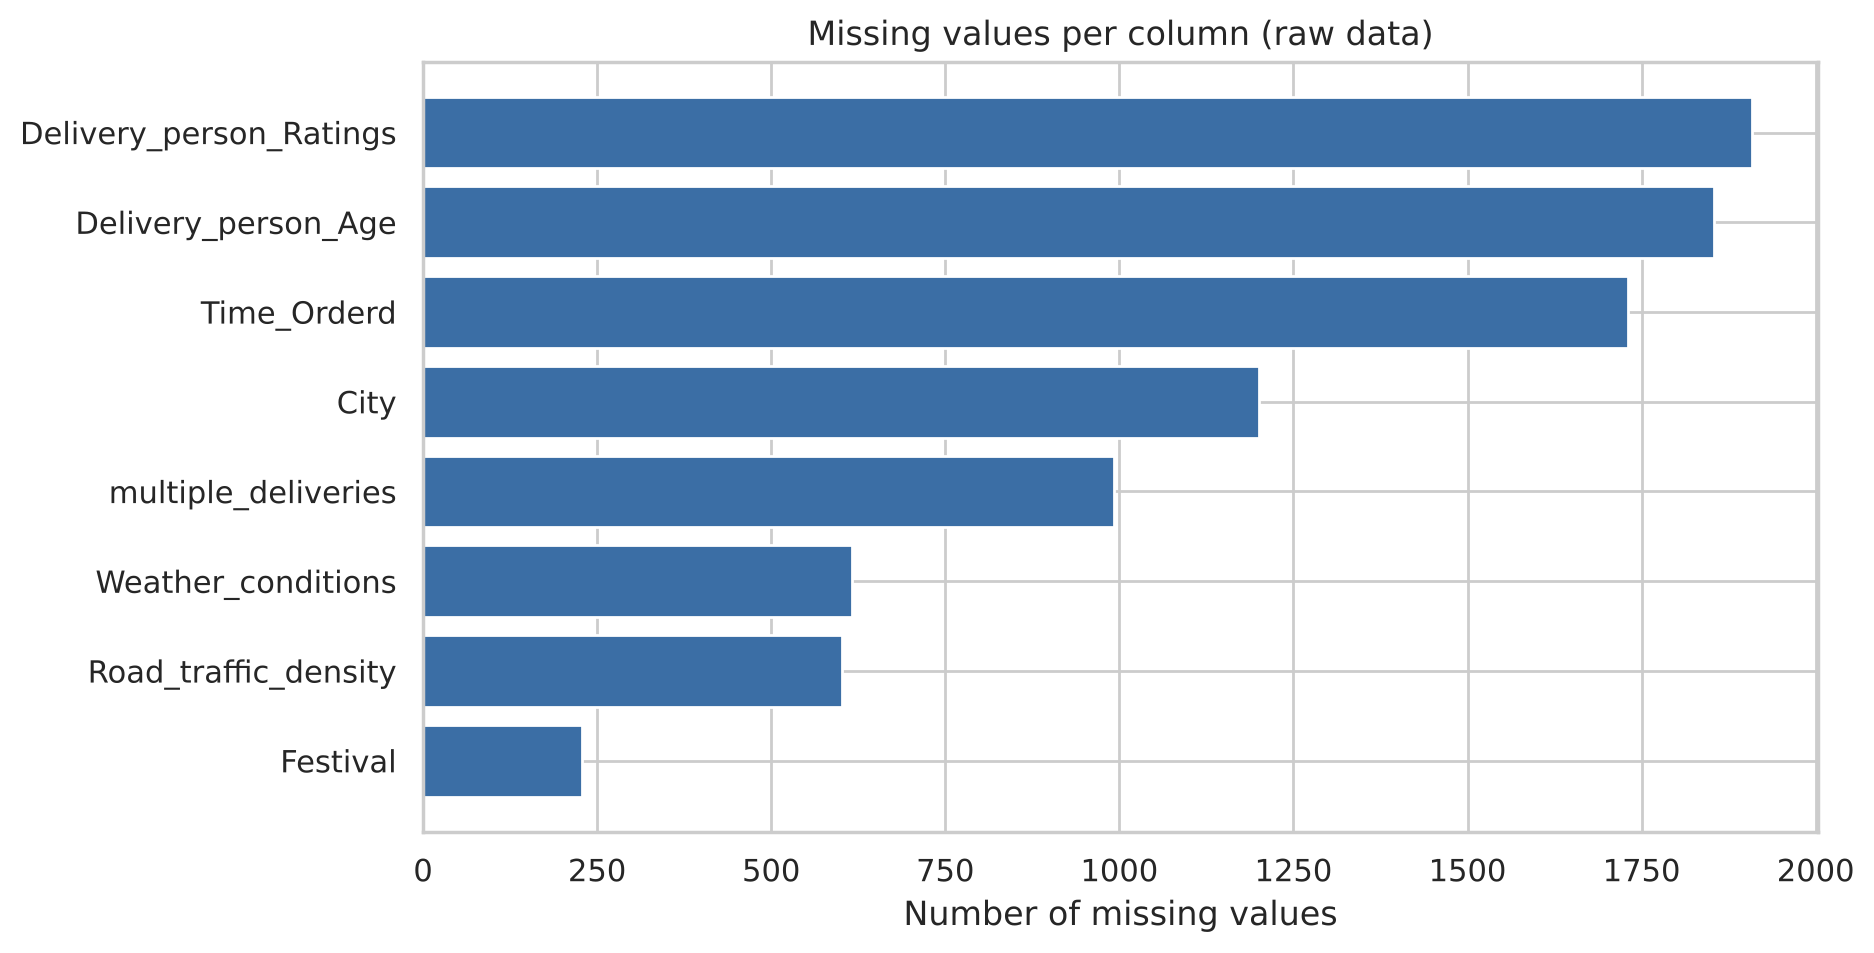

Delivery_person_Ratings    4.19
Delivery_person_Age        4.07
Time_Orderd                3.80
City                       2.63
multiple_deliveries        2.18
Weather_conditions         1.35
Road_traffic_density       1.32
Festival                   0.50
dtype: float64

In [8]:
# 1. Missing values per column (only columns that have some), largest first
missing = raw.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)

# bar chart
plt.figure(figsize=(9, 5))
plt.barh(missing.index, missing.values, color=COLOR)
plt.gca().invert_yaxis()              # largest bar on top
plt.xlabel("Number of missing values")
plt.title("Missing values per column (raw data)")
plt.show()

# same numbers as a table, with percentages
(missing / len(raw) * 100).round(2)

In [9]:
# 2. Coordinates
# India lies roughly between latitude 8 and 37, so a value below 1 is not a real location
zero_coords = (raw["Restaurant_latitude"].abs() < 1) | (raw["Delivery_location_latitude"].abs() < 1)
print("Rows with zero coordinates:", zero_coords.sum())

# all of India has positive latitude and longitude, so a minus sign is a typing error
print("Negative restaurant latitude:", (raw["Restaurant_latitude"] < 0).sum())
print("Negative restaurant longitude:", (raw["Restaurant_longitude"] < 0).sum())

Rows with zero coordinates: 3640
Negative restaurant latitude: 431
Negative restaurant longitude: 162


In [10]:
# 3. Riders younger than 18
young = raw["Delivery_person_Age"] < 18
print("Riders under 18:", young.sum())

# what ratings do these riders have? (all of them are exactly 1.0, so they look like dummy rows)
print(raw.loc[young, "Delivery_person_Ratings"].value_counts())

# 4. Ratings above 5 (the scale is 1 to 5)
print("\nRatings above 5:", (raw["Delivery_person_Ratings"] > 5).sum())

Riders under 18: 38
Delivery_person_Ratings
1.0    38
Name: count, dtype: int64

Ratings above 5: 53


In [11]:
# 5. Time format
# A proper time contains ":" (like 21:55). Excel decimals do not (like 0.8333 or 1)
order_times = raw["Time_Orderd"].dropna().astype(str)
decimal_times = order_times[~order_times.str.contains(":")]

print("Order times in Excel decimal format:", len(decimal_times))
print("Examples:", decimal_times.head(5).tolist())

picked_times = raw["Time_Order_picked"].astype(str)
print("\nPickup times in Excel decimal format:", (~picked_times.str.contains(":")).sum())

Order times in Excel decimal format: 4068
Examples: ['0.458333333', '0.958333333', '0.791666667', '0.875', '0.958333333']

Pickup times in Excel decimal format: 4127


In [12]:
# 6. Spelling mistake in City
print(raw["City"].value_counts())

City
Metropolitian    34087
Urban            10133
Semi-Urban         164
Name: count, dtype: int64


In [13]:
# All problems in one table
issues = pd.DataFrame([
    ["Restaurant or delivery coordinates are zero", zero_coords.sum(), "Drop rows"],
    ["Negative restaurant latitude", (raw["Restaurant_latitude"] < 0).sum(), "Remove minus sign"],
    ["Negative restaurant longitude", (raw["Restaurant_longitude"] < 0).sum(), "Remove minus sign"],
    ["Rider age below 18 (all rated 1.0)", young.sum(), "Drop rows"],
    ["Rider rating above 5", (raw["Delivery_person_Ratings"] > 5).sum(), "Drop rows"],
    ["Order time in Excel decimal format", len(decimal_times), "Convert to HH:MM"],
    ["Pickup time in Excel decimal format", (~picked_times.str.contains(":")).sum(), "Convert to HH:MM"],
    ["City spelled 'Metropolitian'", (raw["City"] == "Metropolitian").sum(), "Rename to 'Metropolitan'"],
    ["Missing values (8 columns)", raw.isna().any(axis=1).sum(), "Keep, fill later inside the model pipeline"],
], columns=["problem", "rows_affected", "action"])

issues["percent_of_rows"] = (issues["rows_affected"] / len(raw) * 100).round(2)
issues

,problem,rows_affected,action,percent_of_rows
0,Restaurant or delivery coordinates are zero,3640,Drop rows,7.99
1,Negative restaurant latitude,431,Remove minus sign,0.95
2,Negative restaurant longitude,162,Remove minus sign,0.36
3,Rider age below 18 (all rated 1.0),38,Drop rows,0.08
4,Rider rating above 5,53,Drop rows,0.12
5,Order time in Excel decimal format,4068,Convert to HH:MM,8.92
6,Pickup time in Excel decimal format,4127,Convert to HH:MM,9.05
7,City spelled 'Metropolitian',34087,Rename to 'Metropolitan',74.78
8,Missing values (8 columns),4225,"Keep, fill later inside the model pipeline",9.27


## Step 3: Clean the data

We fix the problems from step 2 and keep a log of how many rows are left after each fix.

**Why we do not fill missing values here:** missing values are filled later, inside the model pipeline, using only the training data. If we filled them now with averages from the whole dataset, information from the test data would "leak" into training.

In [14]:
# work on a copy so the raw table stays untouched
df = raw.copy()

# rename columns to short, simple names
df = df.rename(columns={
    "ID": "order_id",
    "Delivery_person_ID": "rider_id",
    "Delivery_person_Age": "rider_age",
    "Delivery_person_Ratings": "rider_rating",
    "Restaurant_latitude": "restaurant_lat",
    "Restaurant_longitude": "restaurant_lon",
    "Delivery_location_latitude": "delivery_lat",
    "Delivery_location_longitude": "delivery_lon",
    "Order_Date": "order_date",
    "Time_Orderd": "time_ordered",
    "Time_Order_picked": "time_picked",
    "Weather_conditions": "weather",
    "Road_traffic_density": "traffic",
    "Vehicle_condition": "vehicle_condition",
    "Type_of_order": "order_type",
    "Type_of_vehicle": "vehicle_type",
    "multiple_deliveries": "multiple_deliveries",
    "Festival": "festival",
    "City": "city_type",
    "Time_taken (min)": "delivery_time_min",
})

# the column we want to predict
TARGET = "delivery_time_min"

# the cleaning log: rows left after each step
log = [{"step": "Raw data", "rows_left": len(df)}]

df.columns.tolist()

['order_id',
 'rider_id',
 'rider_age',
 'rider_rating',
 'restaurant_lat',
 'restaurant_lon',
 'delivery_lat',
 'delivery_lon',
 'order_date',
 'time_ordered',
 'time_picked',
 'weather',
 'traffic',
 'vehicle_condition',
 'order_type',
 'vehicle_type',
 'multiple_deliveries',
 'festival',
 'city_type',
 'delivery_time_min']

In [15]:
# Fix 1: remove the minus sign from restaurant coordinates (-22.7 becomes 22.7)
df["restaurant_lat"] = df["restaurant_lat"].abs()
df["restaurant_lon"] = df["restaurant_lon"].abs()
log.append({"step": "Fix negative coordinates (no rows removed)", "rows_left": len(df)})

# Fix 2: drop rows where a latitude is below 1 (zero coordinates)
df = df[(df["restaurant_lat"] >= 1) & (df["delivery_lat"] >= 1)]
log.append({"step": "Drop zero coordinates", "rows_left": len(df)})

print("Rows left:", len(df))

Rows left: 41944


In [16]:
# Fix 3: drop riders under 18
# We write ~(age < 18) instead of (age >= 18) on purpose:
# (age >= 18) would also drop rows where age is missing, and we want to keep those
df = df[~(df["rider_age"] < 18)]
log.append({"step": "Drop riders under 18", "rows_left": len(df)})

# Fix 4: drop ratings above 5 (same trick, so missing ratings are kept)
df = df[~(df["rider_rating"] > 5)]
log.append({"step": "Drop ratings above 5", "rows_left": len(df)})

print("Rows left:", len(df))

Rows left: 41863


In [17]:
# Fix 5: one function that turns any time value into "HH:MM" text
def fix_time(value):
    # missing stays missing
    if pd.isna(value):
        return np.nan

    text = str(value)

    # Case 1: a clock time like "21:55" or "21:55:00"
    if ":" in text:
        parts = text.split(":")
        hours = int(parts[0]) % 24        # % 24 turns hour 24 into hour 0
        minutes = int(parts[1])

    # Case 2: an Excel decimal, which is the fraction of a day passed (0.5 = 12:00 noon)
    else:
        total_minutes = round(float(text) * 24 * 60)   # fraction x 24 h x 60 min
        total_minutes = total_minutes % (24 * 60)       # 1440 min (a full day) wraps to 0
        hours = total_minutes // 60
        minutes = total_minutes % 60

    # :02d writes the number with 2 digits, so 9 becomes "09"
    return f"{hours:02d}:{minutes:02d}"


# test the function on every kind of value we found
for example in ["21:55", "21:55:00", "24:15", "0.8333", "0.458333333", "1", np.nan]:
    print(repr(example), "->", fix_time(example))

'21:55' -> 21:55
'21:55:00' -> 21:55
'24:15' -> 00:15
'0.8333' -> 20:00
'0.458333333' -> 11:00
'1' -> 00:00
nan -> nan


In [18]:
# apply fix_time to every value of both time columns
df["time_ordered"] = df["time_ordered"].apply(fix_time)
df["time_picked"] = df["time_picked"].apply(fix_time)
log.append({"step": "Convert times to HH:MM (no rows removed)", "rows_left": len(df)})

# check: every non-missing time now looks like "HH:MM"
print("All order times in HH:MM format:", df["time_ordered"].dropna().str.match(r"^\d{2}:\d{2}$").all())
print("All pickup times in HH:MM format:", df["time_picked"].dropna().str.match(r"^\d{2}:\d{2}$").all())

All order times in HH:MM format: True
All pickup times in HH:MM format: True


In [19]:
# Fix 6: correct the spelling in city_type
df["city_type"] = df["city_type"].replace("Metropolitian", "Metropolitan")

# Fix 7: drop exact duplicate rows (step 1 found none, this is a safety check)
df = df.drop_duplicates()
log.append({"step": "Fix city spelling + drop duplicates", "rows_left": len(df)})

print(df["city_type"].value_counts())

city_type
Metropolitan    31349
Urban            9253
Semi-Urban        149
Name: count, dtype: int64


In [20]:
# The cleaning log as a table
log_table = pd.DataFrame(log)

# rows removed in a step = rows before it - rows after it
log_table["rows_removed"] = (log_table["rows_left"].shift(1) - log_table["rows_left"]).fillna(0).astype(int)

removed = len(raw) - len(df)
print(f"Total removed: {removed} rows ({removed / len(raw) * 100:.1f}%) | Rows left: {len(df)}")

log_table

Total removed: 3721 rows (8.2%) | Rows left: 41863


,step,rows_left,rows_removed
0,Raw data,45584,0
1,Fix negative coordinates (no rows removed),45584,0
2,Drop zero coordinates,41944,3640
3,Drop riders under 18,41909,35
4,Drop ratings above 5,41863,46
5,Convert times to HH:MM (no rows removed),41863,0
6,Fix city spelling + drop duplicates,41863,0


In [21]:
# Save the clean data for the next notebook (models)
os.makedirs("data/processed", exist_ok=True)
df.to_csv("data/processed/clean_data.csv", index=False)

print("Saved data/processed/clean_data.csv with", len(df), "rows")

Saved data/processed/clean_data.csv with 41863 rows


## Step 4: Exploratory Data Analysis (EDA)

Goal: understand what affects delivery time before building any model.

### 4A. The target: delivery time

In [22]:
# basic statistics of the target
df[TARGET].describe().round(2)

count    41863.00
mean        26.32
std          9.38
min         10.00
25%         19.00
50%         26.00
75%         32.00
max         54.00
Name: delivery_time_min, dtype: float64

Skewness: 0.48


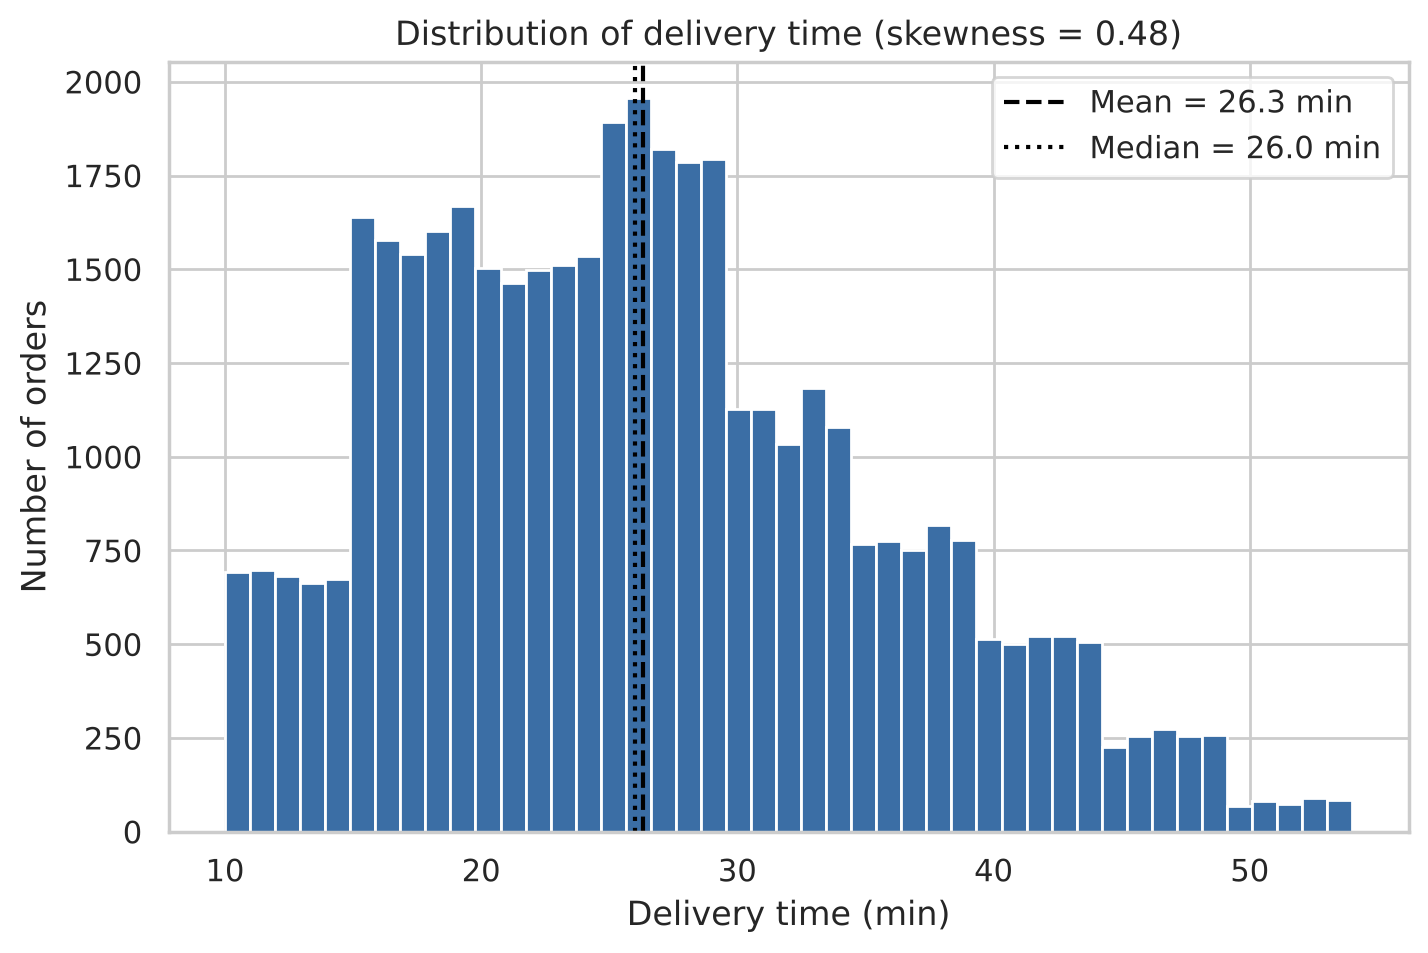

In [23]:
# skewness: 0 = symmetric, above 0 = longer tail on the right
skewness = df[TARGET].skew()
print("Skewness:", round(skewness, 2))

# histogram with mean and median lines
plt.figure(figsize=(8, 5))
plt.hist(df[TARGET], bins=45, color=COLOR, edgecolor="white")
plt.axvline(df[TARGET].mean(), color="black", linestyle="--", label=f"Mean = {df[TARGET].mean():.1f} min")
plt.axvline(df[TARGET].median(), color="black", linestyle=":", label=f"Median = {df[TARGET].median():.1f} min")
plt.xlabel("Delivery time (min)")
plt.ylabel("Number of orders")
plt.title(f"Distribution of delivery time (skewness = {skewness:.2f})")
plt.legend()
plt.show()

Q1 = 19.0 | Q3 = 32.0 | IQR = 13.0 | Upper limit = 51.5
Outliers (slow orders above the limit): 247


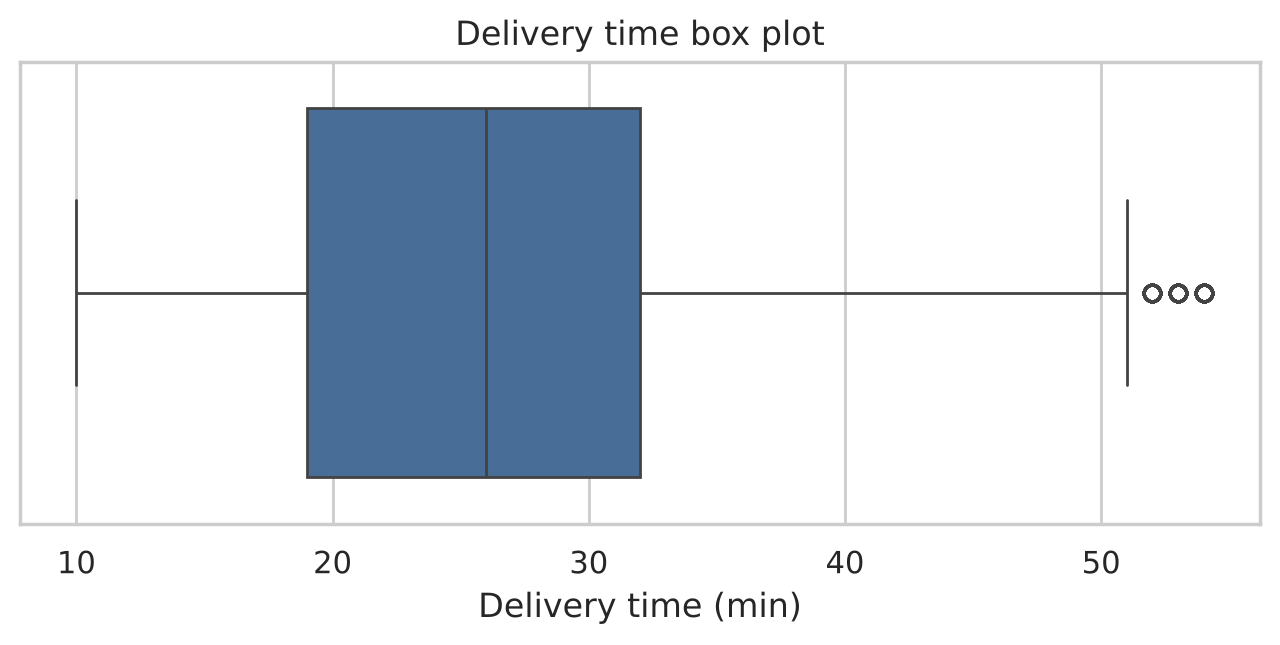

Outliers on festival days: 85
Outliers with 2 or more extra orders: 105
Outliers in semi-urban areas: 49


In [24]:
# Outliers with the IQR rule: below Q1 - 1.5*IQR or above Q3 + 1.5*IQR
q1 = df[TARGET].quantile(0.25)
q3 = df[TARGET].quantile(0.75)
iqr = q3 - q1
upper_limit = q3 + 1.5 * iqr
outliers = df[df[TARGET] > upper_limit]

print("Q1 =", q1, "| Q3 =", q3, "| IQR =", iqr, "| Upper limit =", upper_limit)
print("Outliers (slow orders above the limit):", len(outliers))

# box plot (outliers show as dots on the right)
plt.figure(figsize=(8, 3))
sns.boxplot(x=df[TARGET], color=COLOR)
plt.xlabel("Delivery time (min)")
plt.title("Delivery time box plot")
plt.show()

# Are these outliers mistakes, or real slow deliveries with a reason?
print("Outliers on festival days:", (outliers["festival"] == "Yes").sum())
print("Outliers with 2 or more extra orders:", (outliers["multiple_deliveries"] >= 2).sum())
print("Outliers in semi-urban areas:", (outliers["city_type"] == "Semi-Urban").sum())

**What we see:**
- Delivery time runs from 10 to 54 min, with a mean of 26.3 and a median of 26.0.
- The skewness of 0.48 is only a mild right tail, so we don't need a log transform.
- The 247 outliers (above 51.5 min) are real slow deliveries with clear reasons (festival days, extra orders, semi-urban areas). We **keep them**. Removing them would teach the model that slow deliveries never happen.

### 4B. Numeric columns

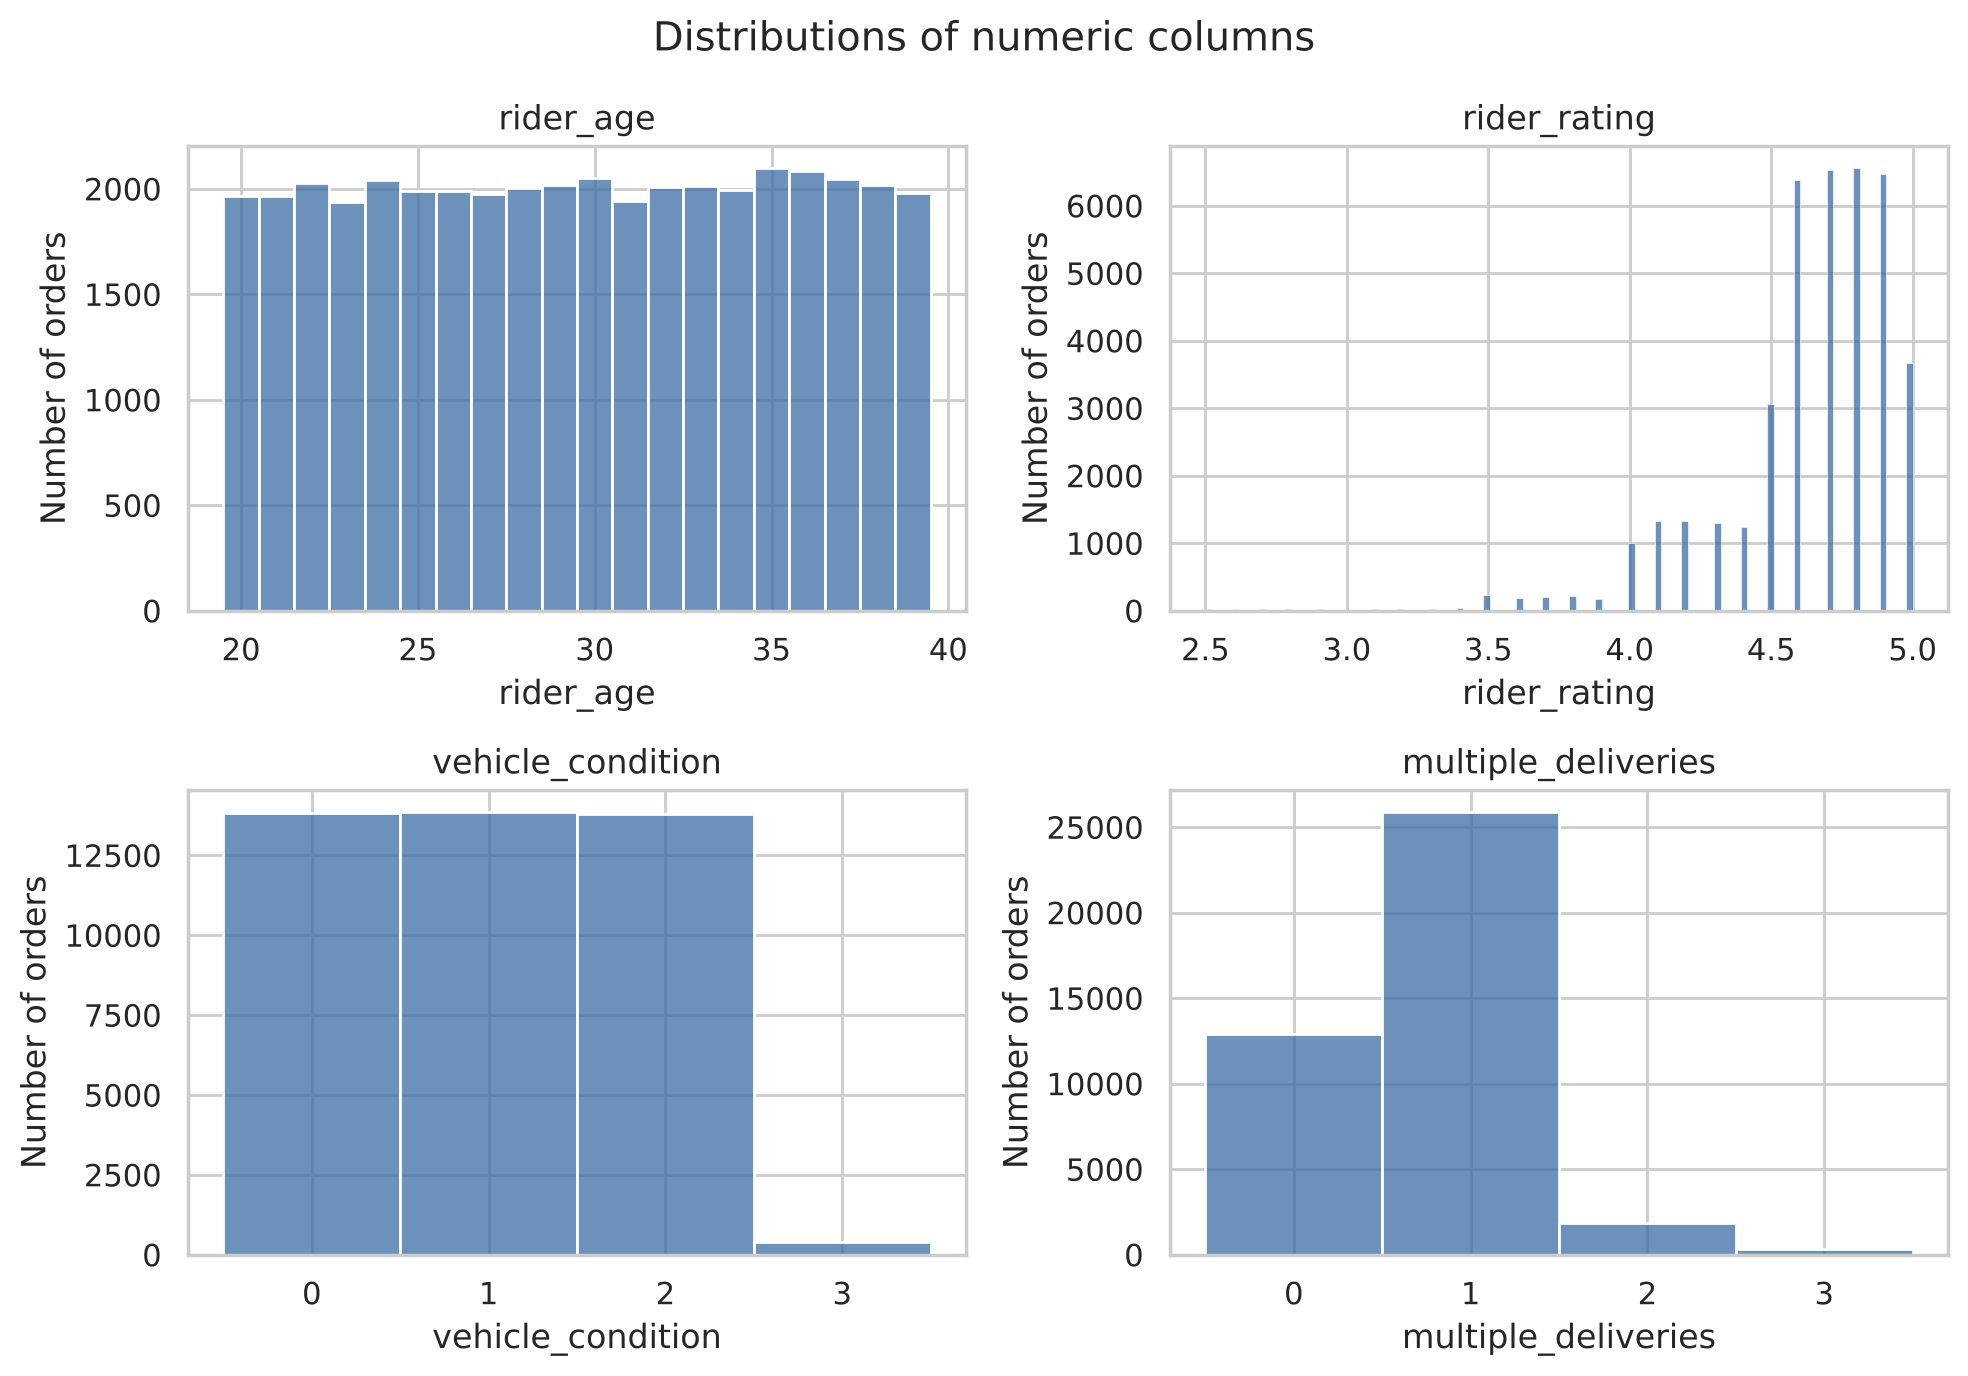

rider_age             -0.01
rider_rating          -1.79
vehicle_condition      0.06
multiple_deliveries    0.32
dtype: float64

In [25]:
numeric_columns = ["rider_age", "rider_rating", "vehicle_condition", "multiple_deliveries"]

# 2 x 2 grid of small histograms
fig, axes = plt.subplots(2, 2, figsize=(10, 7))

# axes.flatten() turns the 2 x 2 grid into a simple list of 4 charts
for ax, column in zip(axes.flatten(), numeric_columns):
    # discrete=True gives one bar per whole number (good for 0, 1, 2, 3)
    sns.histplot(df[column].dropna(), ax=ax, color=COLOR, discrete=(column != "rider_rating"))
    ax.set_title(column)
    ax.set_ylabel("Number of orders")

plt.suptitle("Distributions of numeric columns")
plt.tight_layout()
plt.show()

# skewness of each numeric column
df[numeric_columns].skew().round(2)

**What we see:** rider age is spread evenly from 20 to 39. Most ratings are between 4.5 and 5 (a left skew of -1.79). Vehicle condition 3 is rare (400 orders), and most riders carry 0 or 1 extra order.

### 4C. Delivery time vs each category

One helper function draws a box plot and prints the numbers, so we don't repeat the same lines 8 times.

In [26]:
def plot_by_category(column, title, order=None):
    # if no order is given, sort the boxes by median delivery time (fastest first)
    if order is None:
        order = df.groupby(column)[TARGET].median().sort_values().index.tolist()

    plt.figure(figsize=(8, 5))
    sns.boxplot(data=df, x=column, y=TARGET, order=order, color=COLOR)

    # write the average above each box
    means = df.groupby(column)[TARGET].mean()
    for position, category in enumerate(order):
        plt.text(position, 56, f"avg {means[category]:.1f}", ha="center", fontsize=9)

    plt.ylim(0, 60)
    plt.ylabel("Delivery time (min)")
    plt.title(title)
    plt.show()

    # print count, average and median for each category
    print(df.groupby(column)[TARGET].agg(["count", "mean", "median"]).round(1))

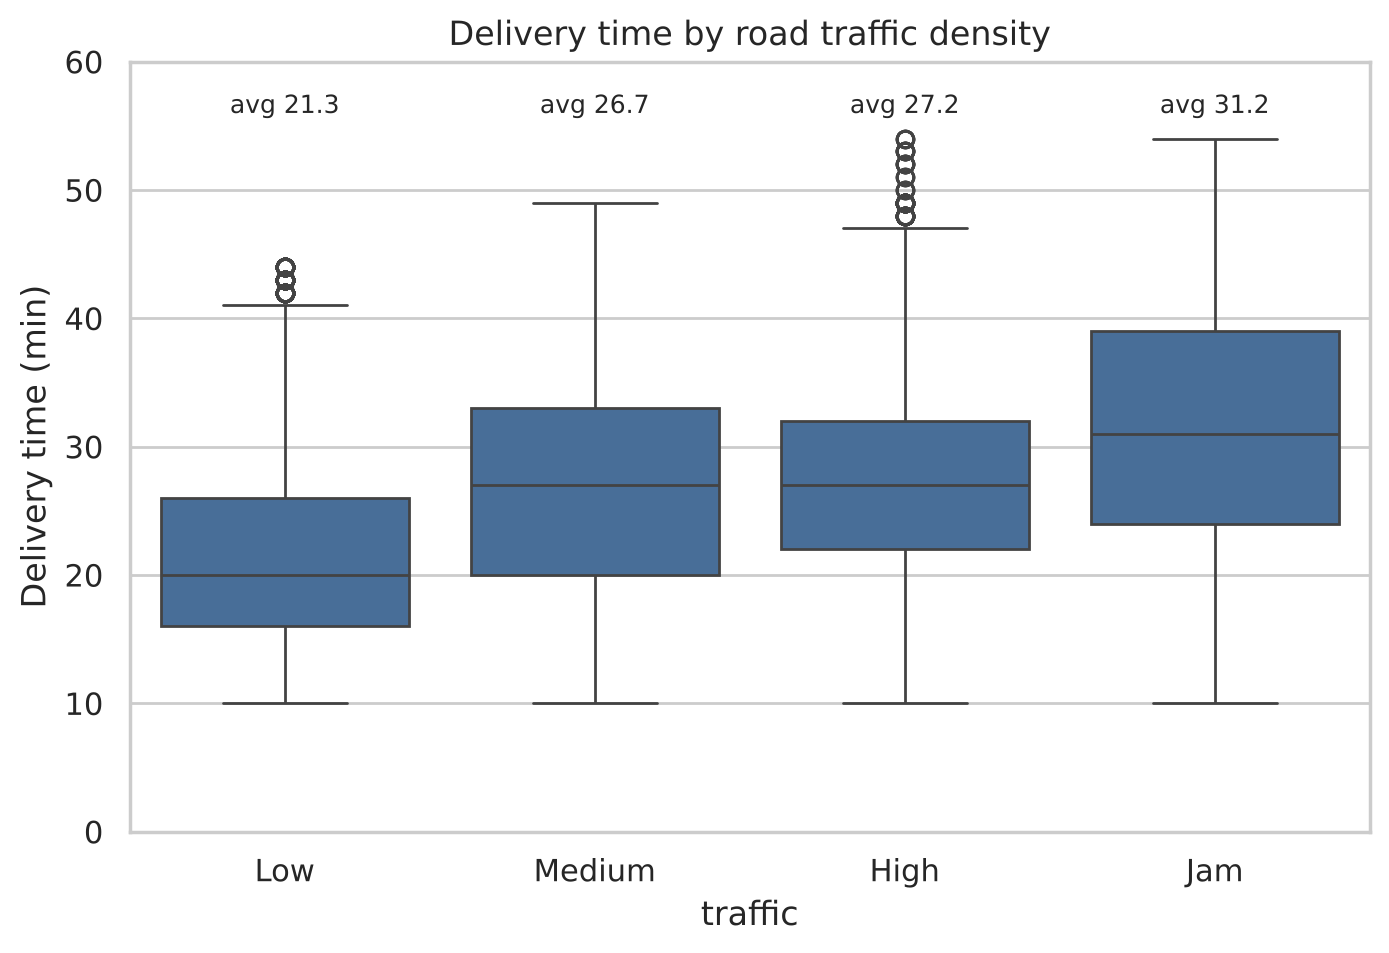

         count  mean  median
traffic                     
High      4069  27.2    27.0
Jam      13039  31.2    31.0
Low      14199  21.3    20.0
Medium   10082  26.7    27.0


In [27]:
plot_by_category("traffic", "Delivery time by road traffic density", order=["Low", "Medium", "High", "Jam"])

**Traffic:** Low 21.3, Medium 26.7, High 27.2, Jam 31.2 min. A jam adds about 10 minutes compared to low traffic. Medium and High are almost the same.

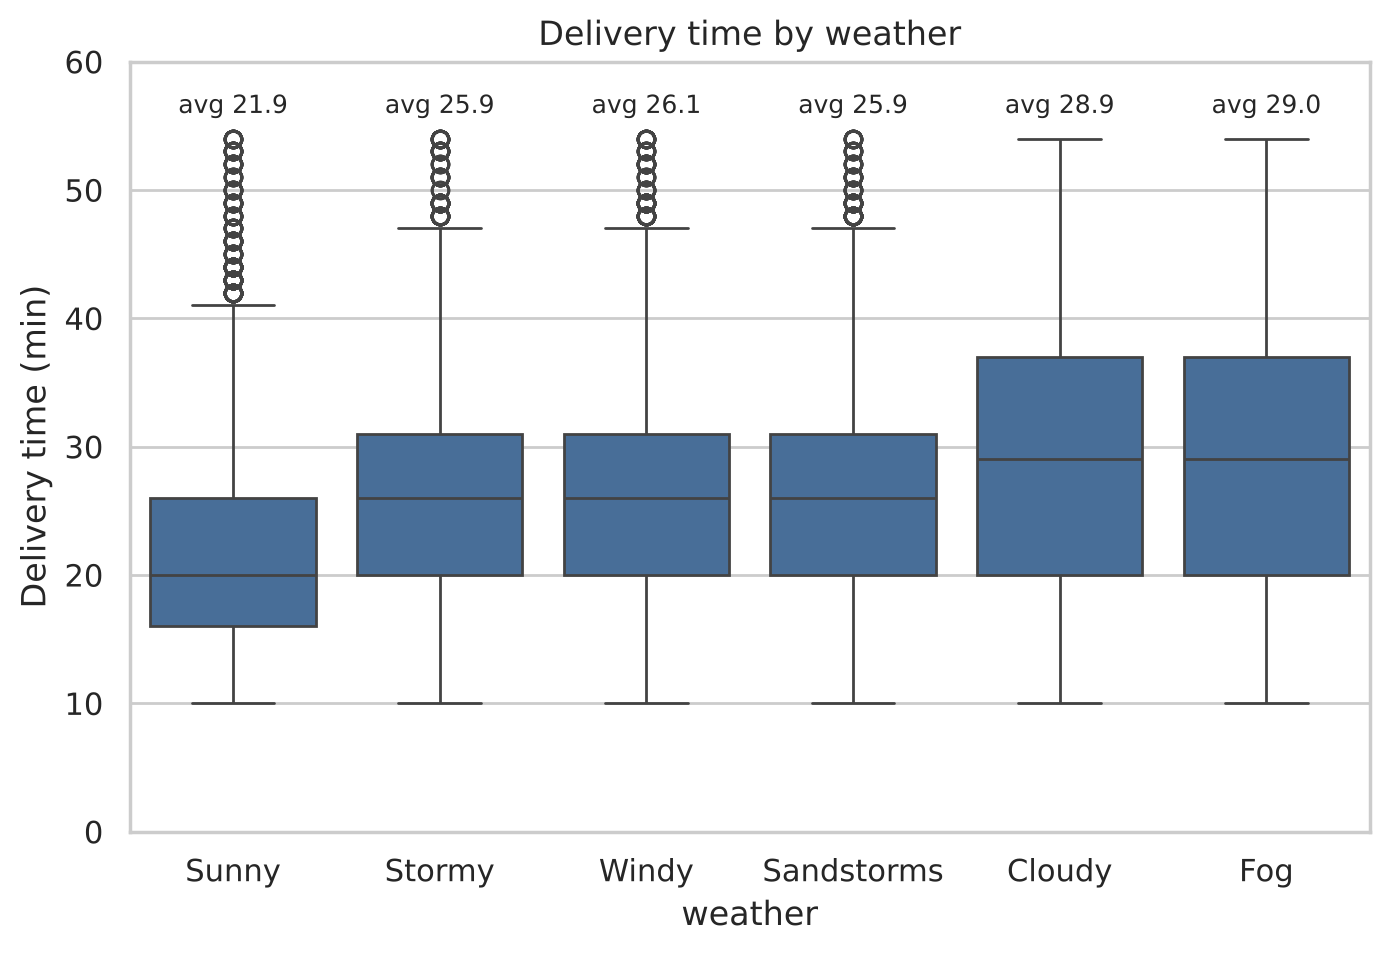

            count  mean  median
weather                        
Cloudy       6929  28.9    29.0
Fog          7011  29.0    29.0
Sandstorms   6905  25.9    26.0
Stormy       6972  25.9    26.0
Sunny        6726  21.9    20.0
Windy        6832  26.1    26.0


In [28]:
plot_by_category("weather", "Delivery time by weather")

**Weather:** Sunny is the fastest (21.9 min). Fog (29.0) and cloudy weather (28.9) are the slowest. Stormy, windy and sandstorm conditions are all near 26 min.

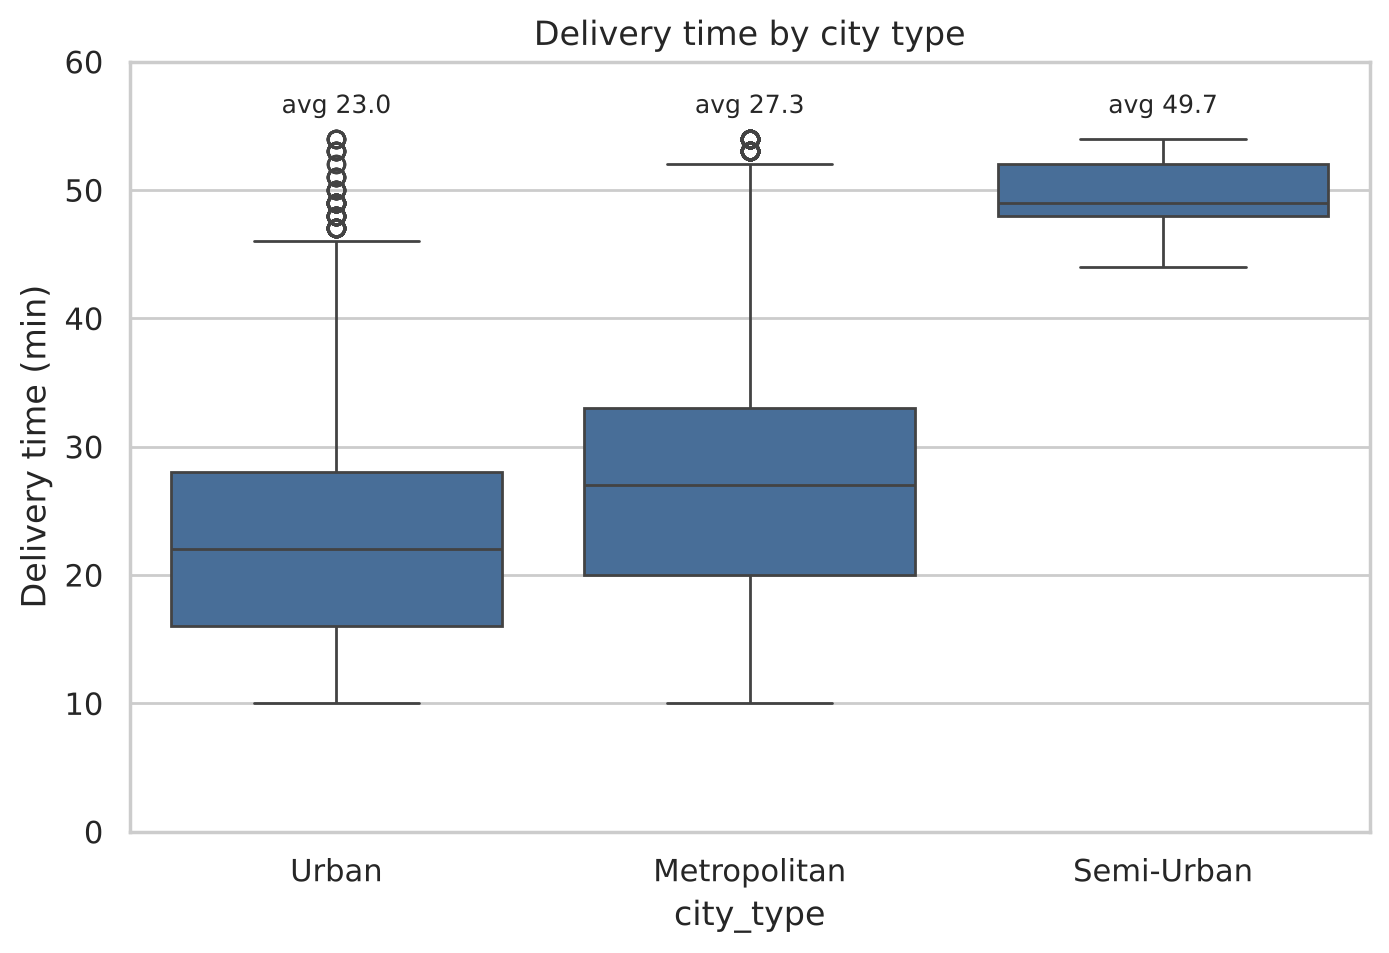

              count  mean  median
city_type                        
Metropolitan  31349  27.3    27.0
Semi-Urban      149  49.7    49.0
Urban          9253  23.0    22.0


In [29]:
plot_by_category("city_type", "Delivery time by city type")

**City type:** Urban 23.0 and Metropolitan 27.3 min. Semi-Urban averages 49.7 min, but there are only 149 such orders, so treat that number with care.

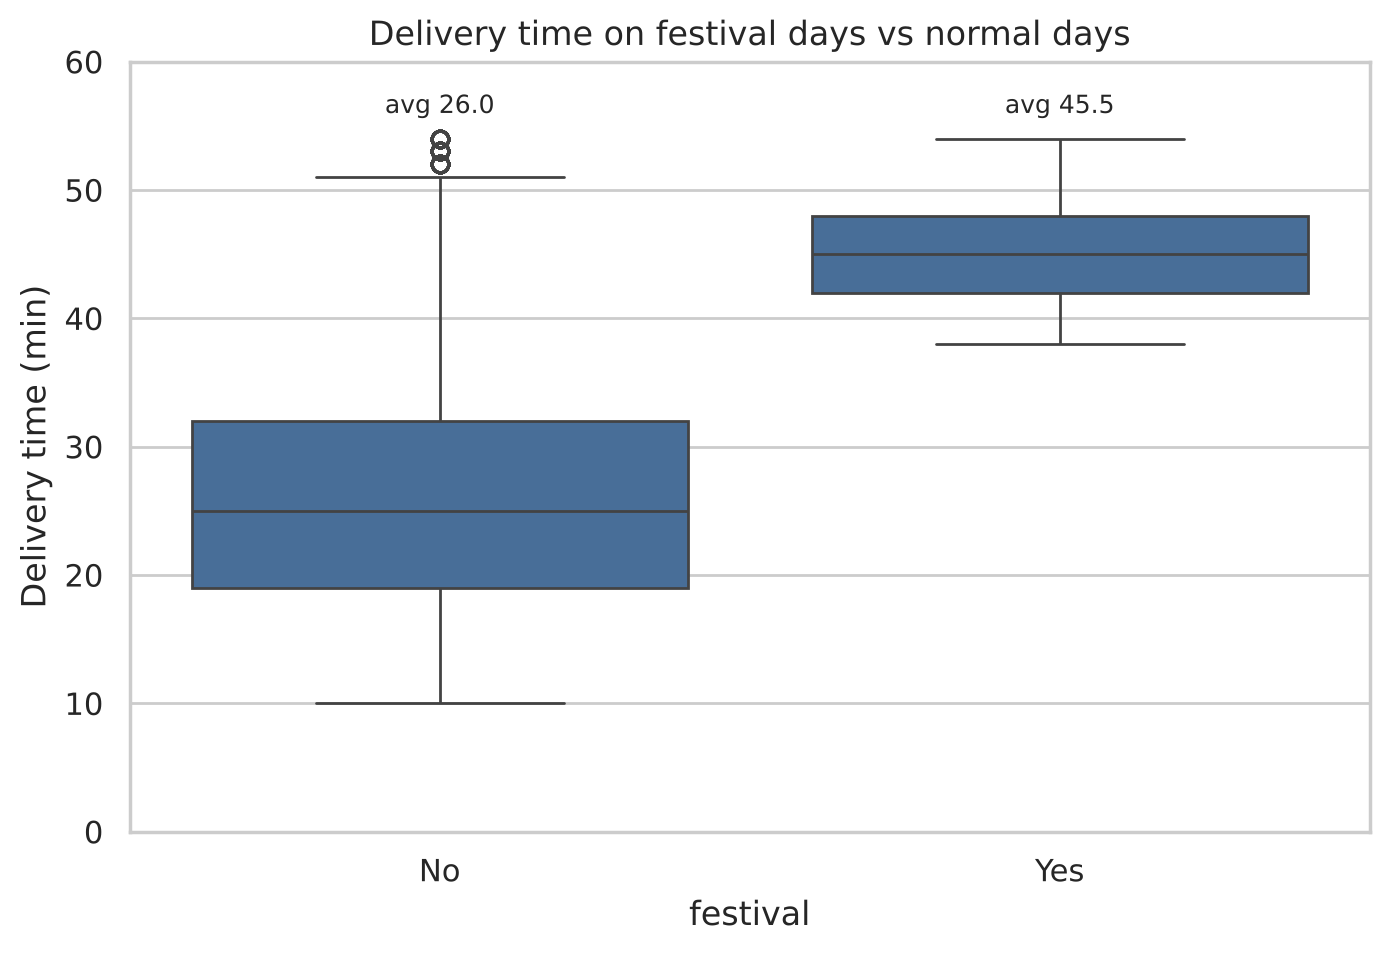

          count  mean  median
festival                     
No        40827  26.0    25.0
Yes         821  45.5    45.0


In [30]:
plot_by_category("festival", "Delivery time on festival days vs normal days", order=["No", "Yes"])

**Festival:** 45.5 min on festival days against 26.0 on normal days, almost 20 minutes slower. There are only 821 festival orders, but the effect is huge.

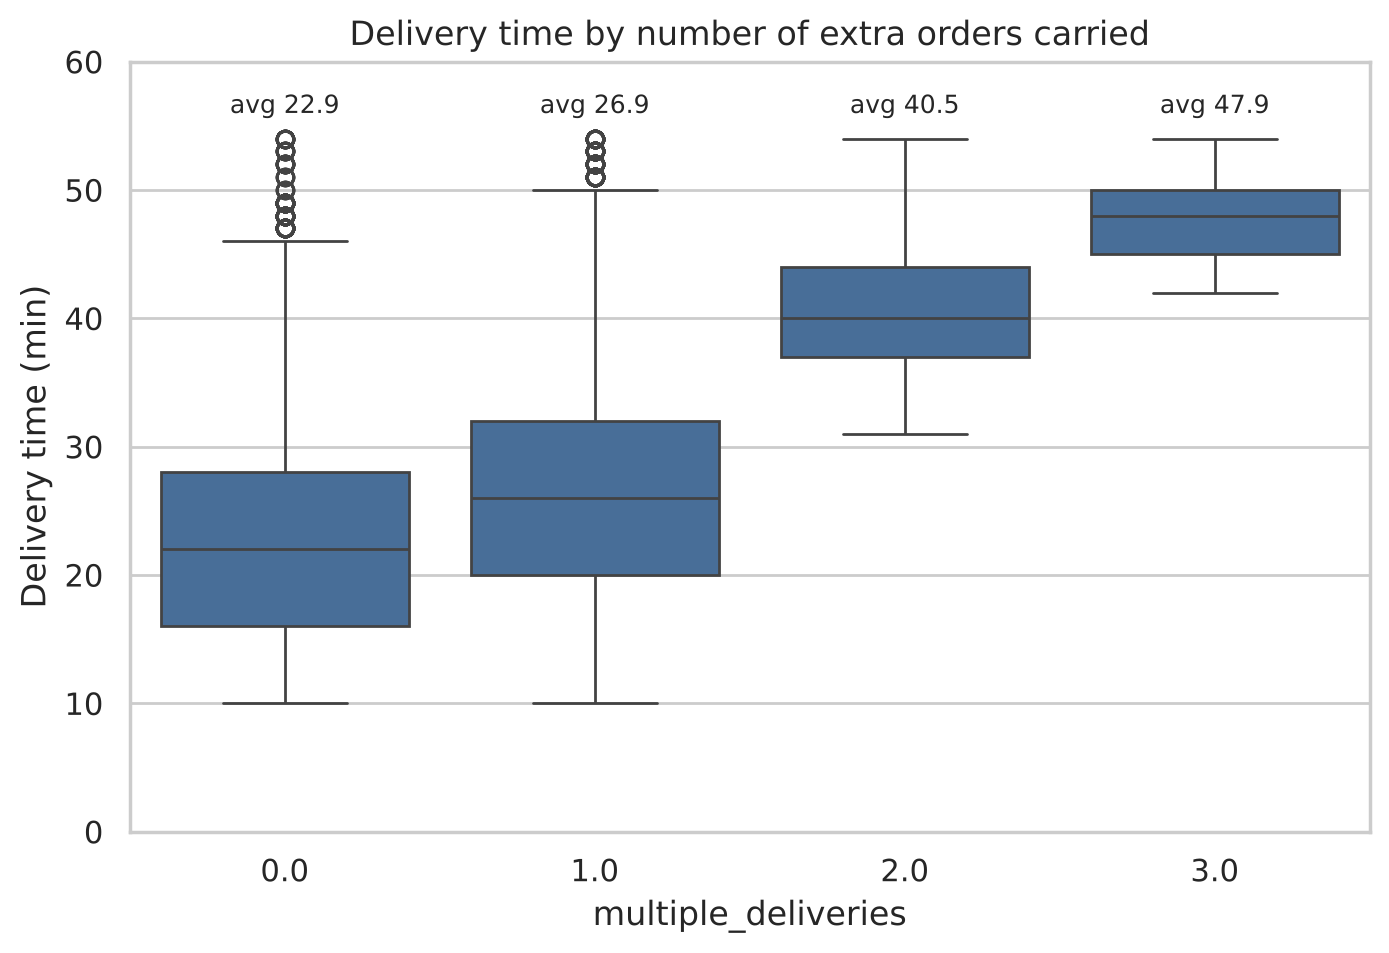

                     count  mean  median
multiple_deliveries                     
0.0                  12918  22.9    22.0
1.0                  25875  26.9    26.0
2.0                   1838  40.5    40.0
3.0                    327  47.9    48.0


In [31]:
plot_by_category("multiple_deliveries", "Delivery time by number of extra orders carried", order=[0.0, 1.0, 2.0, 3.0])

**Multiple deliveries:** 0 extra = 22.9, 1 = 26.9, 2 = 40.5, 3 = 47.9 min. Going from 1 to 2 extra orders adds about 14 minutes. This is the strongest numeric factor.

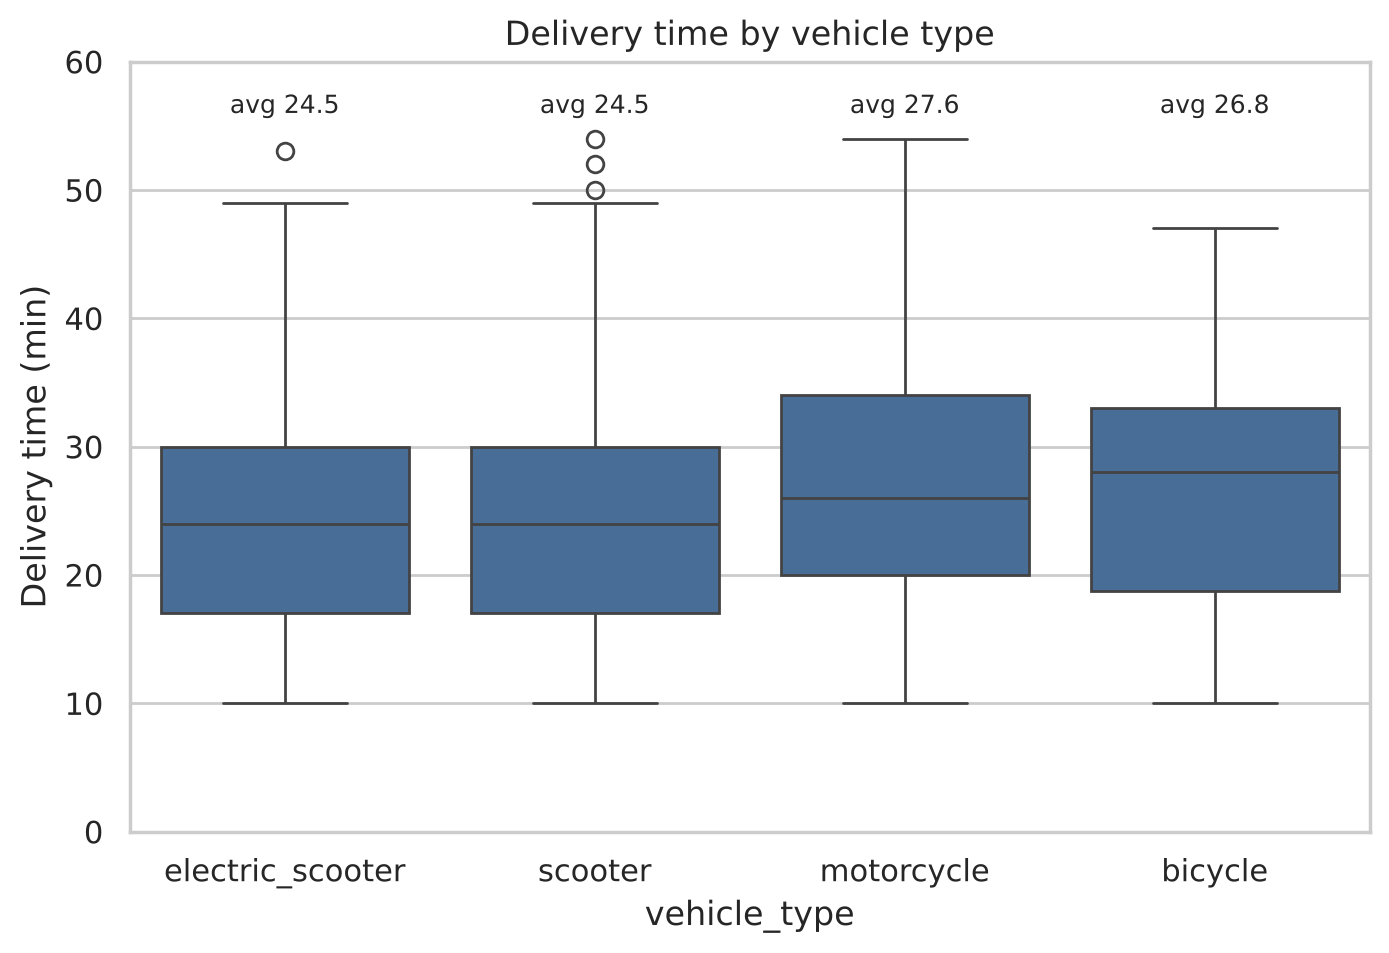

                  count  mean  median
vehicle_type                         
bicycle              48  26.8    28.0
electric_scooter   3434  24.5    24.0
motorcycle        24382  27.6    26.0
scooter           13999  24.5    24.0


In [32]:
plot_by_category("vehicle_type", "Delivery time by vehicle type")

**Vehicle type:** scooters and electric scooters average 24.5 min, motorcycles 27.6. Bicycles have only 48 orders, too few to read much into.

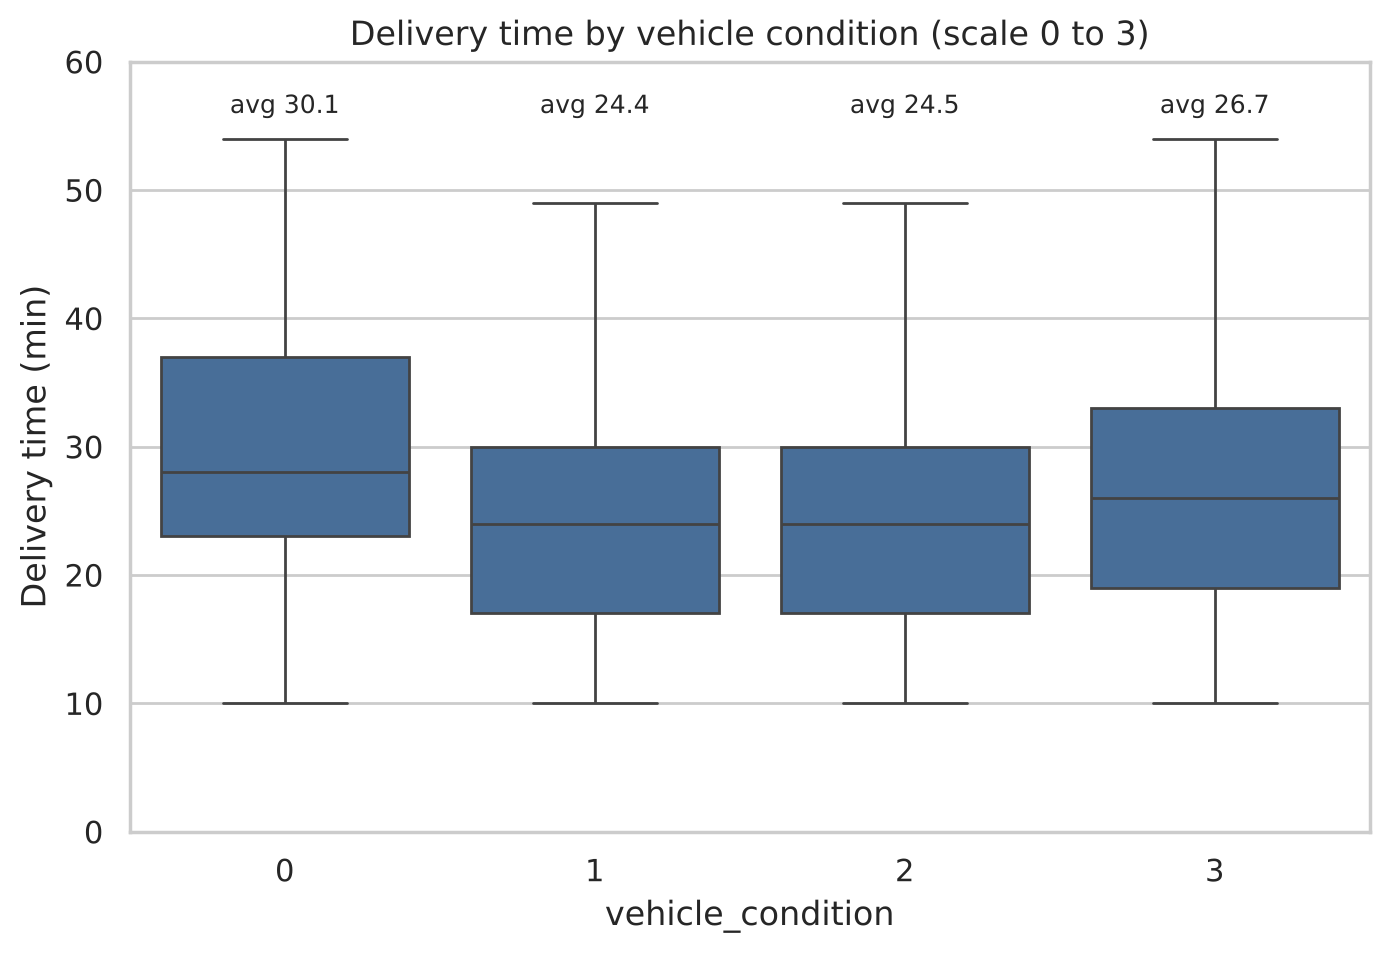

                   count  mean  median
vehicle_condition                     
0                  13811  30.1    28.0
1                  13849  24.4    24.0
2                  13803  24.5    24.0
3                    400  26.7    26.0


In [33]:
plot_by_category("vehicle_condition", "Delivery time by vehicle condition (scale 0 to 3)", order=[0, 1, 2, 3])

**Vehicle condition:** condition 0 is the slowest (30.1 min), 1 and 2 are both about 24.4 min, and 3 is 26.7 min (only 400 orders). The dataset does not say which end of the scale is "good", so we only describe the pattern.

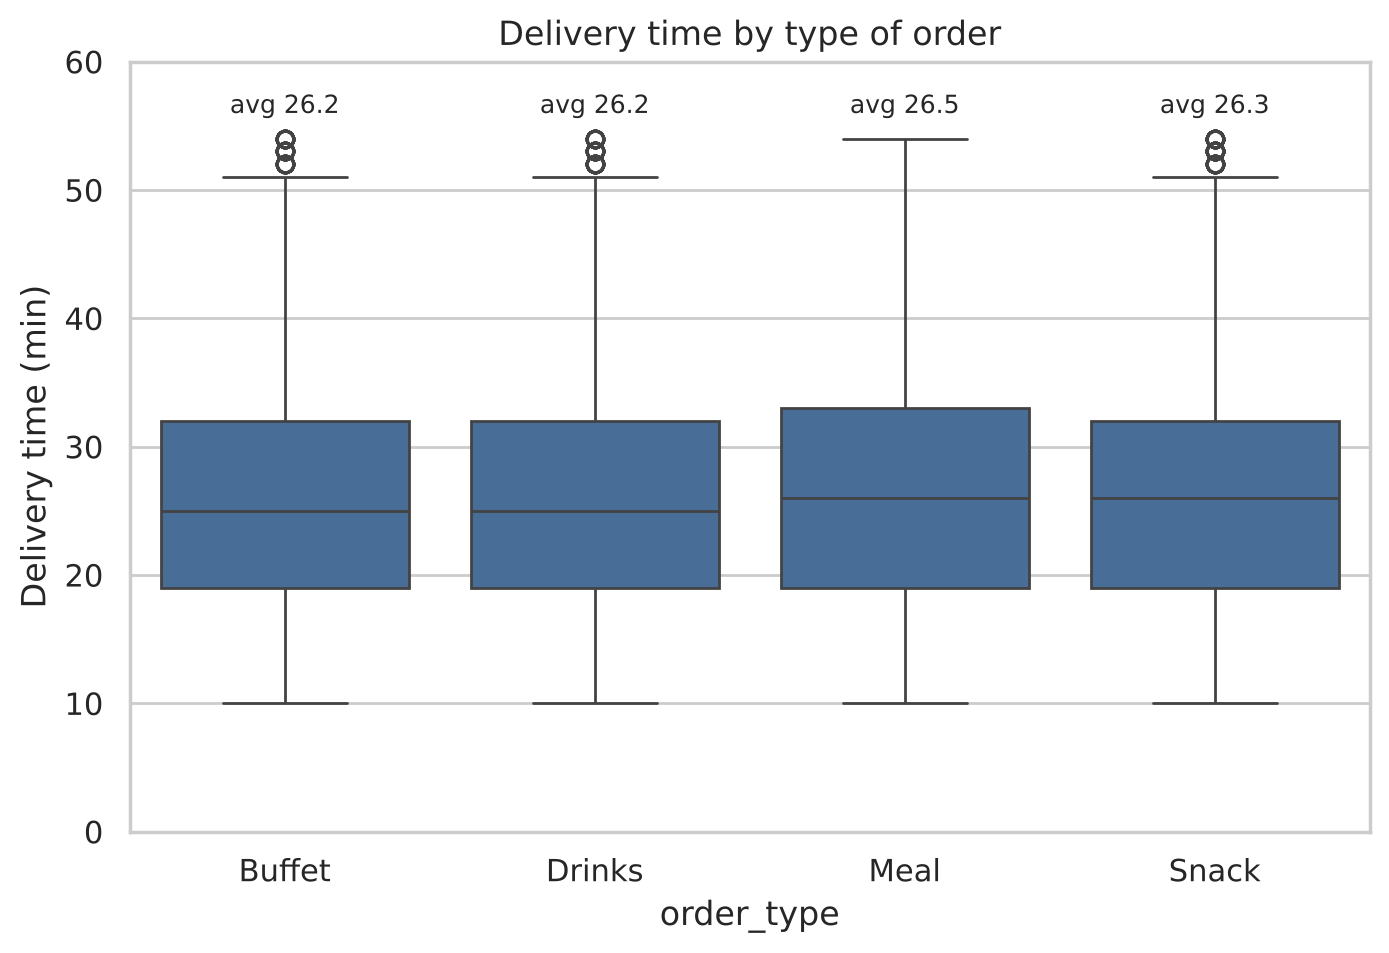

            count  mean  median
order_type                     
Buffet      10347  26.2    25.0
Drinks      10420  26.2    25.0
Meal        10502  26.5    26.0
Snack       10594  26.3    26.0


In [34]:
plot_by_category("order_type", "Delivery time by type of order")

**Order type:** Buffet 26.2, Drinks 26.2, Meal 26.5, Snack 26.3 min. Type of order has **no effect** on delivery time. We keep the column for now and let feature importance confirm this later.

### 4D. Rider rating and rider age

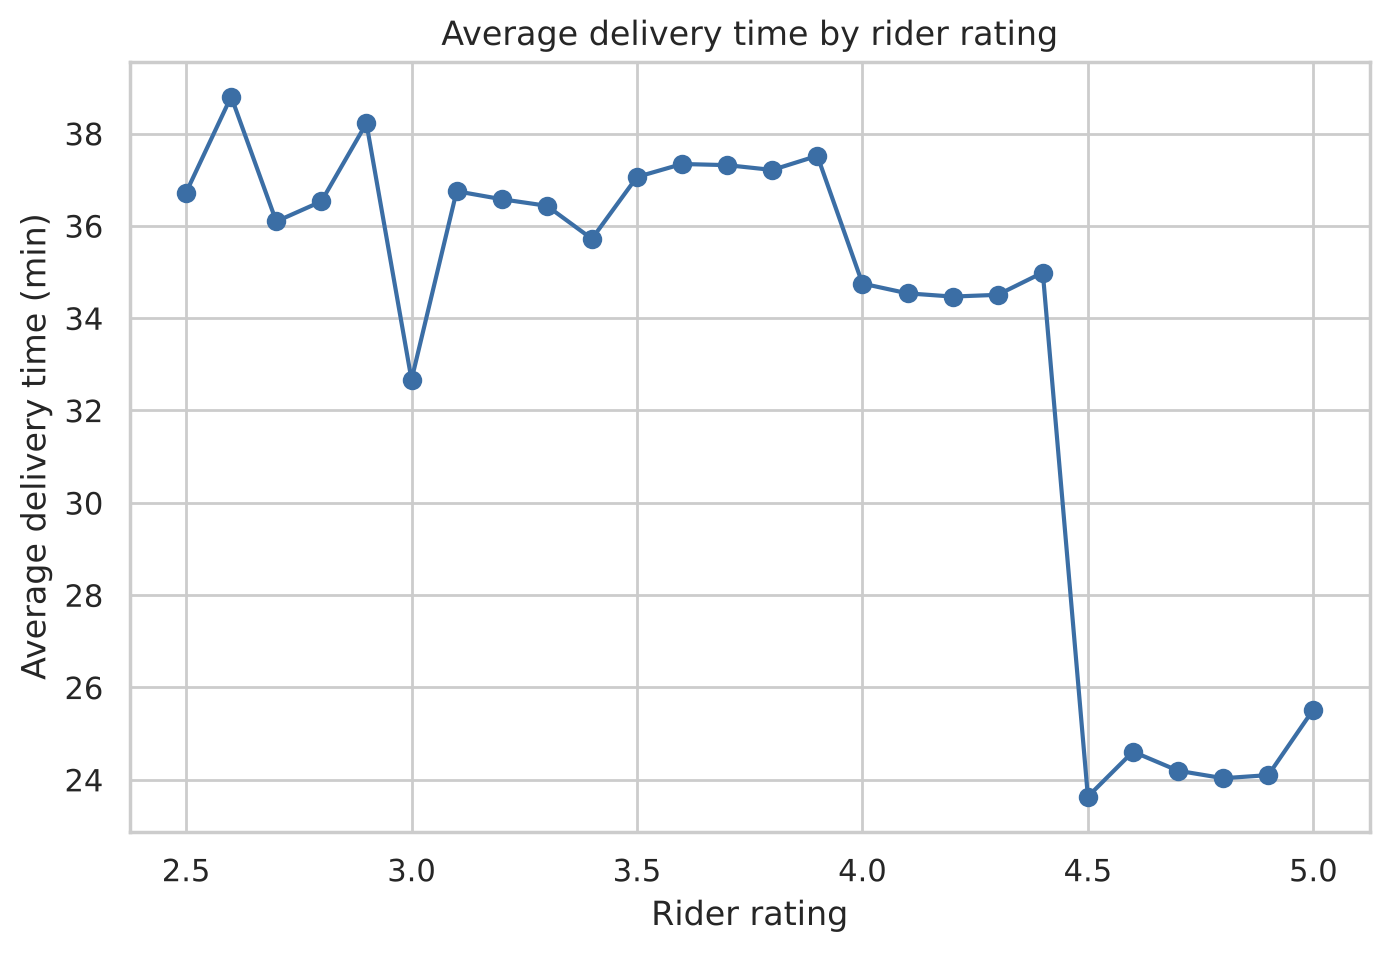

In [35]:
# average delivery time for each rating value
rating_means = df.groupby("rider_rating")[TARGET].mean()

plt.figure(figsize=(8, 5))
plt.plot(rating_means.index, rating_means.values, marker="o", color=COLOR)
plt.xlabel("Rider rating")
plt.ylabel("Average delivery time (min)")
plt.title("Average delivery time by rider rating")
plt.show()

**Rider rating:** higher-rated riders are faster, but the change happens as one **sharp step at 4.5**. Below 4.5, averages sit around 33 to 39 min. From 4.5 up, they drop to about 24 to 25.5 min.

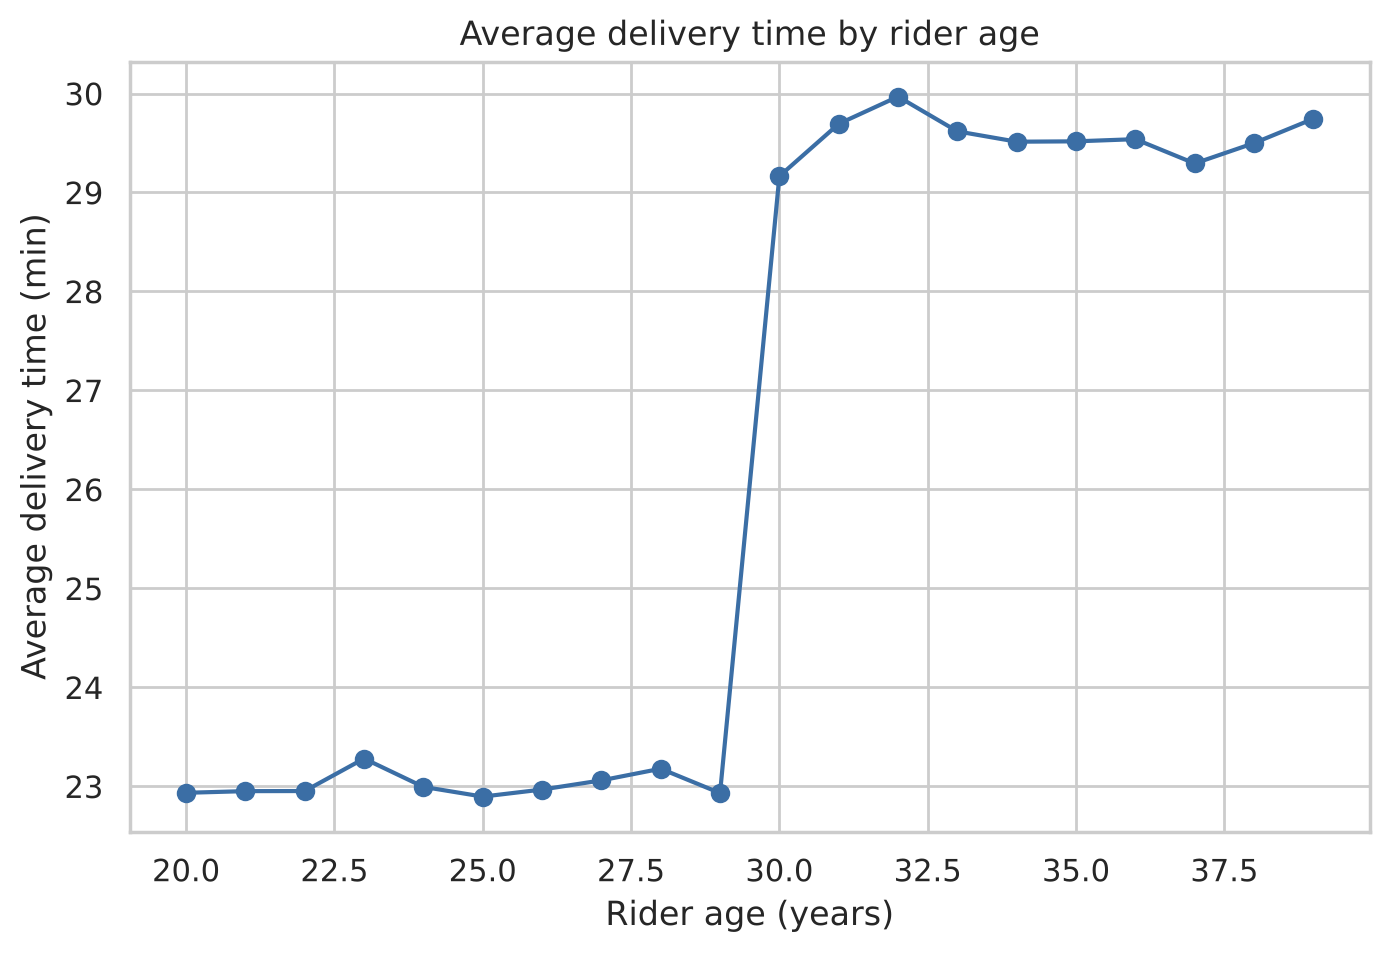

In [36]:
# average delivery time for each age
age_means = df.groupby("rider_age")[TARGET].mean()

plt.figure(figsize=(8, 5))
plt.plot(age_means.index, age_means.values, marker="o", color=COLOR)
plt.xlabel("Rider age (years)")
plt.ylabel("Average delivery time (min)")
plt.title("Average delivery time by rider age")
plt.show()

**Rider age:** again a **sharp step, this time at 30**. Riders aged 20 to 29 average about 23 min, and riders aged 30 to 39 average about 29 to 30 min.

Such clean steps are unusual in real life, which suggests rules built into how the dataset was made. This matters for model choice. Tree models (Random Forest, XGBoost) handle steps naturally, while linear regression can only draw straight lines. So we expect tree models to do clearly better.

### 4E. Time of day

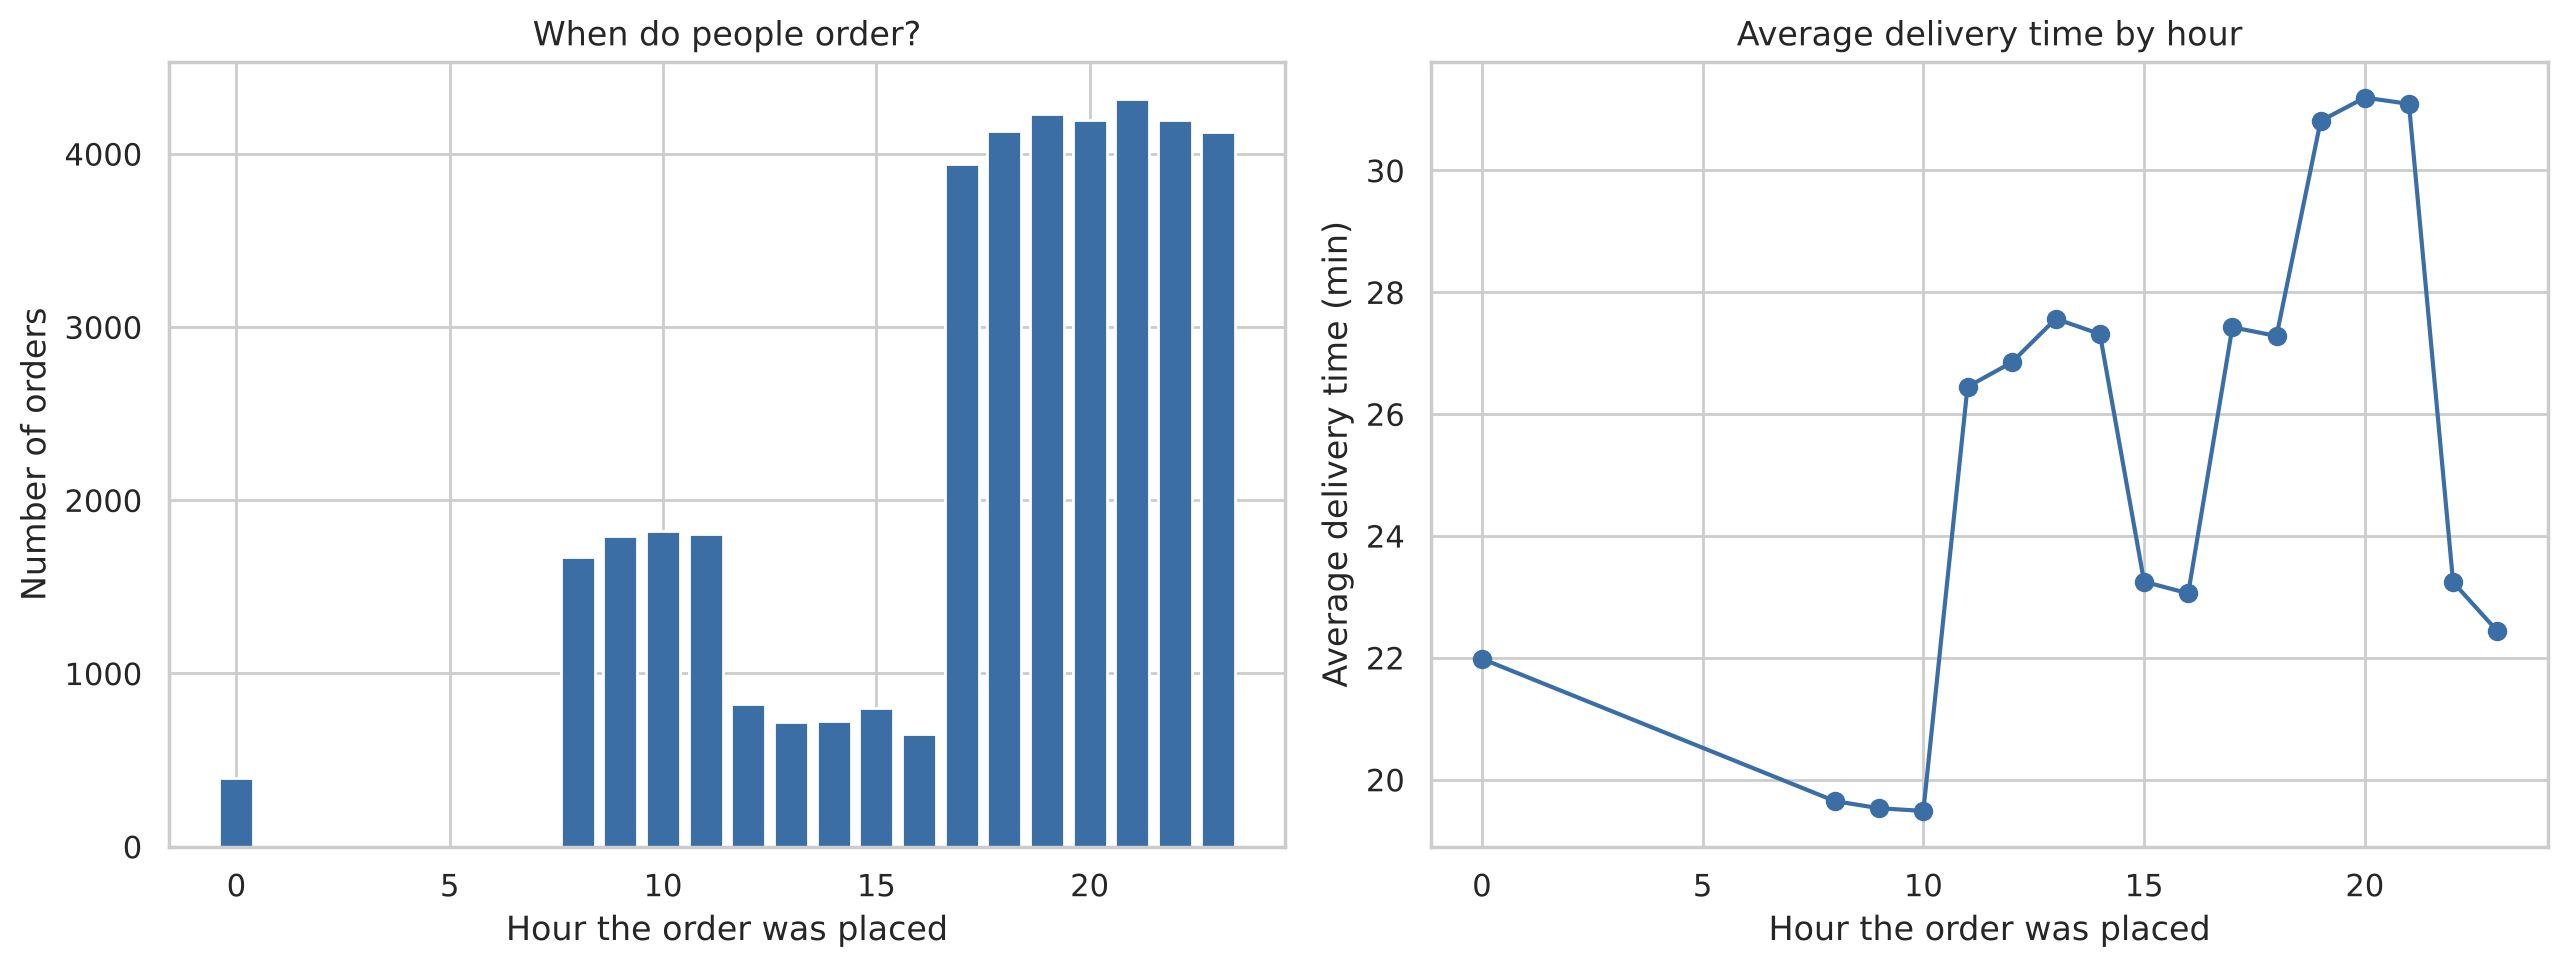

In [37]:
# time_ordered looks like "21:55", so the first 2 characters are the hour
df["order_hour"] = pd.to_numeric(df["time_ordered"].str[:2])

orders_per_hour = df["order_hour"].value_counts().sort_index()
time_per_hour = df.groupby("order_hour")[TARGET].mean()

# two charts side by side
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].bar(orders_per_hour.index, orders_per_hour.values, color=COLOR)
axes[0].set_xlabel("Hour the order was placed")
axes[0].set_ylabel("Number of orders")
axes[0].set_title("When do people order?")

axes[1].plot(time_per_hour.index, time_per_hour.values, marker="o", color=COLOR)
axes[1].set_xlabel("Hour the order was placed")
axes[1].set_ylabel("Average delivery time (min)")
axes[1].set_title("Average delivery time by hour")

plt.tight_layout()
plt.show()

**Time of day:**
- Orders come in two waves: morning (8 to 11) and evening (17 to 23). There are no orders between 1 am and 7 am.
- Orders placed from 8 to 10 am are the fastest (about 19.5 min). The slowest hours are 19 to 21 (about 31 min), the evening rush.
- The effect rises and then falls, so a single correlation number (0.19) understates it. A tree model can still learn it.

### 4F. Correlation between numeric columns

Correlation runs from -1 to +1. Plus means both rise together; minus means one falls as the other rises.

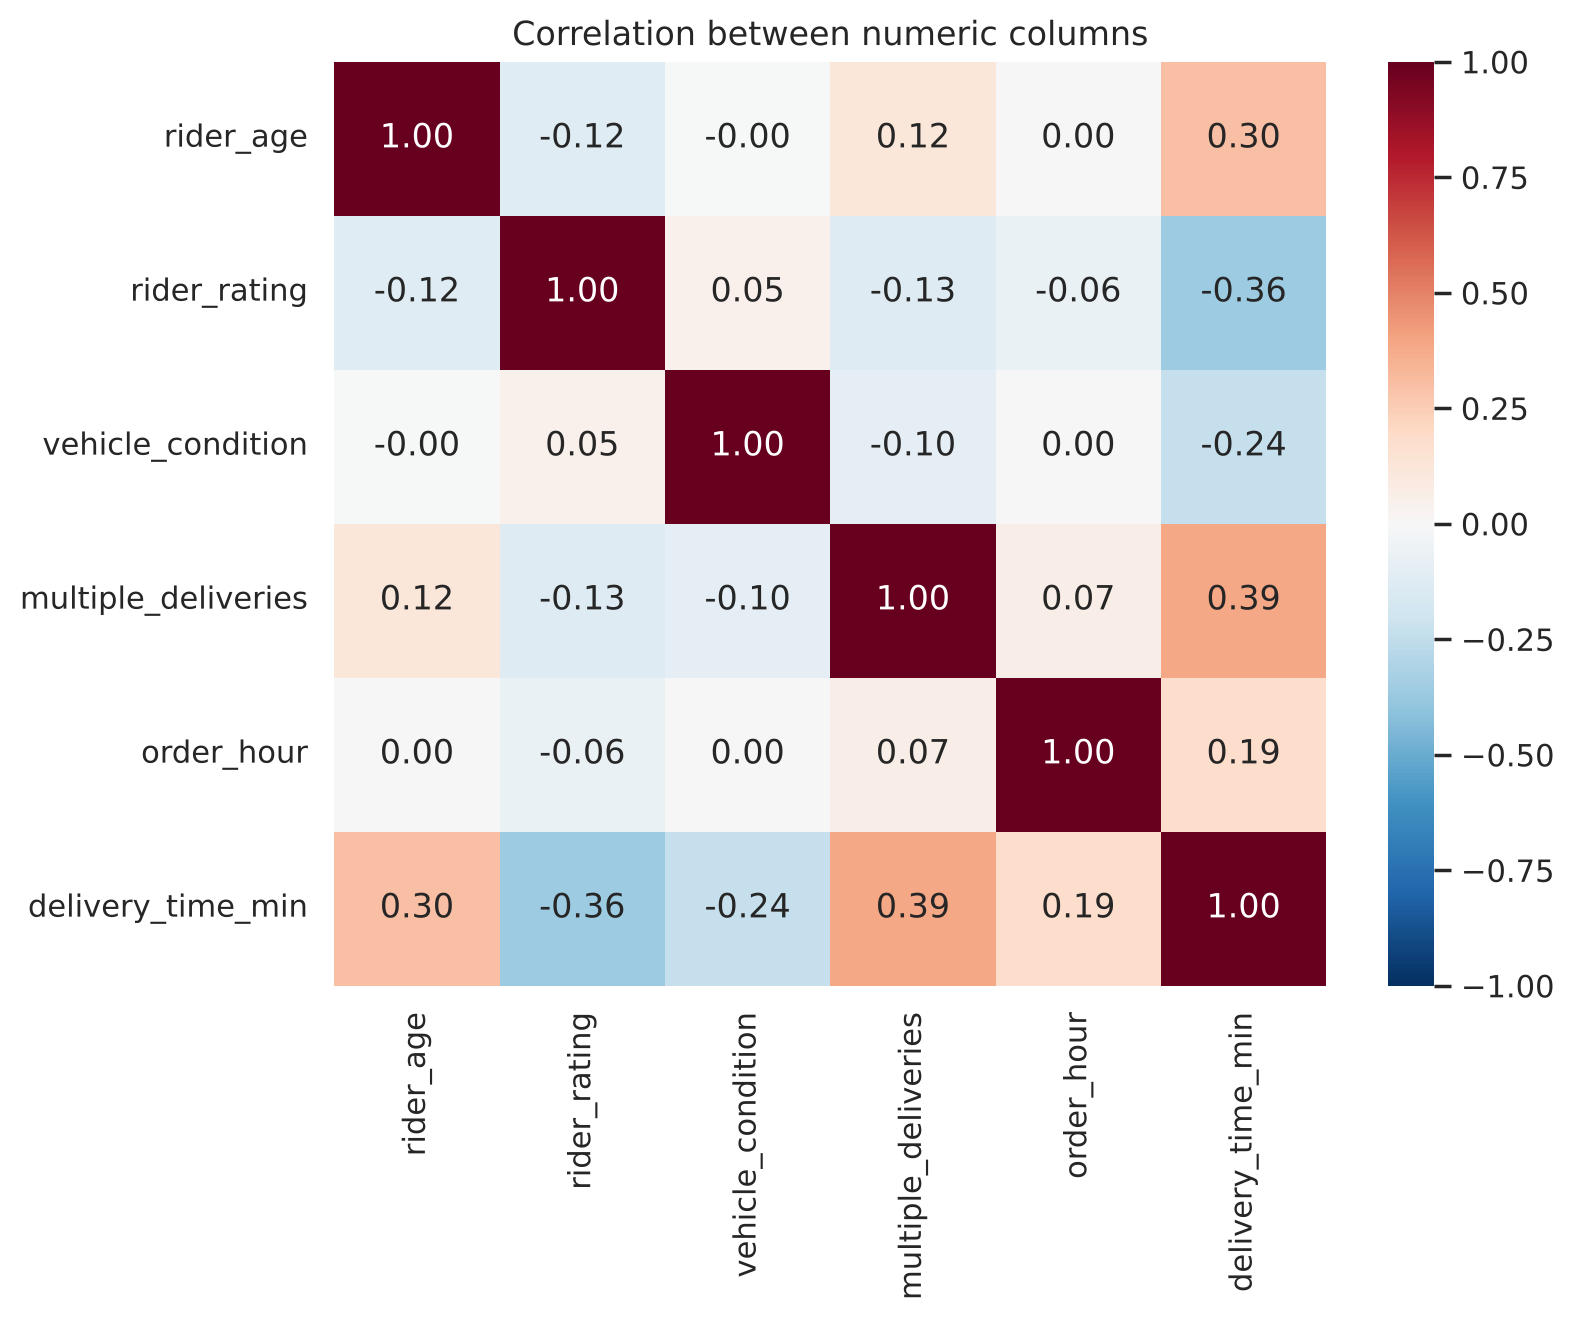

multiple_deliveries    0.387
rider_rating          -0.363
rider_age              0.303
vehicle_condition     -0.235
order_hour             0.185
Name: delivery_time_min, dtype: float64

In [38]:
correlation = df[["rider_age", "rider_rating", "vehicle_condition",
                  "multiple_deliveries", "order_hour", TARGET]].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1)
plt.title("Correlation between numeric columns")
plt.show()

# correlation of each column with delivery time, strongest first
corr_target = correlation[TARGET].drop(TARGET)
corr_target.reindex(corr_target.abs().sort_values(ascending=False).index).round(3)

**What we see:** multiple deliveries (+0.39), rider rating (-0.36) and rider age (+0.30) relate most to delivery time. The input columns barely correlate with each other (the strongest pair is only about 0.13). So we don't have the "highly correlated features" problem, and PCA is not needed, which keeps every feature explainable.

## Summary of EDA findings

| Factor | Effect on delivery time |
|---|---|
| Festival day | 45.5 min vs 26.0 min on normal days |
| Extra orders carried | 22.9 min (0 extra) up to 47.9 min (3 extra) |
| Traffic | 21.3 min (Low) up to 31.2 min (Jam) |
| Weather | 21.9 min (Sunny) up to 29.0 min (Fog) |
| Rider rating | Sharp drop at 4.5 |
| Rider age | Sharp jump at 30 |
| Time of day | Slowest from 19 to 21 (about 31 min) |
| Order type | No effect |

<br>

## What this means for the next steps

1. Fill missing values inside the model pipeline (median for numbers, most frequent value for categories), using training data only.
2. Keep the target as it is. It is only mildly skewed, and its outliers are real.
3. Build new features: distance between restaurant and customer, order hour, a peak-hour flag, and day of week.
4. Distance has not been checked yet because it is not a column. We calculate it in the next notebook.
5. Expect tree models to beat linear regression, because the strongest patterns are steps and curves, not straight lines.